# Heterogeneous front tracking playground

Choose a heterogeneity $g$, a level spacing δ, initial data and a window, then explore the fronts of $u_t + (g(x)|u|^p)_x = 0$, $p>1$ (default $p=2$).

**Run all cells from top to bottom** (Jupyter: *Run → Run All Cells*; Colab:
*Runtime → Run all*). The first cells install any missing NumPy, Matplotlib
or ipywidgets. This notebook carries a readable snapshot of the solver, so it
runs on its own; inside a project checkout it uses `src/hetfront` instead.
GitHub shows saved figures only; open the notebook in Jupyter or Colab to use
the controls.

In [1]:
# Install only missing dependencies into this notebook's Python environment.
import sys, subprocess, importlib.util
if sys.version_info < (3, 10):
    raise RuntimeError("Use Python 3.10 or newer")
requirements = {"numpy": "numpy>=1.24", "matplotlib": "matplotlib>=3.7", "ipywidgets": "ipywidgets>=8,<9"}
missing = [spec for name, spec in requirements.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if "google.colab" in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Standalone source snapshot. Generated by tools/build_notebooks.py; do not edit here.
from pathlib import Path
import tempfile, hashlib, json
BUNDLED_SOURCES = {'__init__.py': '"""Heterogeneous front tracking for u_t + (g(x) h(u))_x = 0 with piecewise-affine g.\n\nh(u) = u² by default, or |u|^p with p > 1 (``MultiplicativeFlux(..., power=p)``).\nThe derivative of g is discretised (g_Δ is the nodal interpolant), so on each\ncell fronts are straight lines in σ = |g_Δ|^{(p-1)/p}; for p = 2, σ = sqrt|g_Δ|\nand w = σu solves Burgers\' equation. Event times come from linear equations.\nCorners of g_Δ emit no waves; zeros of g are absorbing interfaces.\n\nPublic API (read the modules in this order):\n\n- ``PiecewiseAffine``      (heterogeneity.py)  g_Δ on the line or a circle\n- ``MultiplicativeFlux``   (flux.py)           g_Δ |u|^p with flux levels θ = kδ\n- ``trajectory``, ``PowerLaw`` (trajectory.py) closed-form front laws\n- ``solve_riemann``        (riemann.py)        shock or δ-fan between levels\n- ``Front``, ``Interface`` (fronts.py)\n- ``HeteroFrontTracker``   (solver.py)         whole-line driver\n- ``PeriodicHeteroFrontTracker``, ``Circle`` (periodic.py, domains.py)\n- ``visualization``        (matplotlib plots, imported on demand)\n"""\nfrom .heterogeneity import PiecewiseAffine\nfrom .flux import MultiplicativeFlux\nfrom .riemann import solve_riemann\nfrom .fronts import Front, Interface\nfrom .solver import HeteroFrontTracker, Piece\nfrom .domains import Circle\nfrom .periodic import PeriodicHeteroFrontTracker\nfrom . import trajectory\nfrom .trajectory import PowerLaw\n\n__version__ = "0.1.0"\n__all__ = [\n    "PiecewiseAffine", "MultiplicativeFlux", "solve_riemann", "Front", "Interface",\n    "HeteroFrontTracker", "Piece", "Circle", "PeriodicHeteroFrontTracker", "trajectory", "PowerLaw",\n]\n', '_validation.py': '"""Shared validation for lattice levels and mesh sizes."""\n\nimport numbers\n\nimport numpy as np\n\n\ndef positive_count(value, name):\n    """Reject fractional/bool counts instead of silently truncating a mesh."""\n    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Integral) or value < 1:\n        raise ValueError(f"{name} must be a positive integer")\n    return int(value)\n\n\ndef integer_levels(values):\n    """Validate a one-dimensional integer lattice input before conversion.\n\n    A fractional level is a different initial condition, not a harmless type\n    conversion. Float inputs are accepted only when exactly integral. The open\n    upper bound avoids float64 rounding int64.max up to the overflow boundary.\n    """\n    values = np.asarray(values)\n    if values.ndim != 1 or values.dtype.kind not in "iuf":\n        raise ValueError("levels must be a one-dimensional array of finite integers")\n    if values.dtype.kind == "f":\n        invalid = (not np.all(np.isfinite(values)) or np.any(values != np.floor(values))\n                   or np.any(values < -(2. ** 63)) or np.any(values >= 2. ** 63))\n    elif values.dtype.kind == "u":\n        invalid = np.any(values > np.iinfo(np.int64).max)\n    else:\n        invalid = False  # signed NumPy integer dtypes fit in int64\n    if invalid:\n        raise ValueError("levels must be finite integers representable as int64")\n    return values.astype(np.int64)\n', 'domains.py': '"""Compact geometry independent of the numerical scheme (mirrors fronttrack.periodic.Circle)."""\n\nfrom dataclasses import dataclass\nimport math\n\nimport numpy as np\n\n\n@dataclass(frozen=True)\nclass Circle:\n    """Flat circle R/(length Z), represented on the chart [origin, origin + length)."""\n\n    length: float = 1.0\n    origin: float = 0.0\n\n    def __post_init__(self):\n        if not math.isfinite(self.length) or self.length <= 0:\n            raise ValueError("length must be positive and finite")\n        if (not math.isfinite(self.origin) or not math.isfinite(self.origin + self.length)\n                or self.origin + self.length <= self.origin):\n            raise ValueError("origin and endpoint must be finite and distinguishable")\n\n    @property\n    def dimension(self):\n        return 1\n\n    @property\n    def volume(self):\n        return self.length\n\n    def wrap(self, points):\n        """Map finite coordinates into [origin, origin + length), same shape."""\n        points = np.asarray(points, dtype=float)\n        if not np.all(np.isfinite(points)):\n            raise ValueError("coordinates must be finite")\n        result = self.origin + np.remainder(points - self.origin, self.length)\n        # remainder can return exactly `length` for tiny negative inputs.\n        result = np.where(result >= self.origin + self.length, self.origin, result)\n        return float(result) if points.ndim == 0 else result\n', 'examples.py': '"""Ready-made experiments, shared by the CLI, the tests and the notebooks.\n\nEach ``Example`` builds a fresh tracker from three resolution parameters:\nδ (flux-level spacing), the number of g-mesh nodes, and the number of data\ncells. It also records an observation window, a final time and the power p of\nh(u) = |u|^p. The xu² examples are exact solutions only for p = 2.\n"""\n\nfrom dataclasses import dataclass, field\nimport math\n\nimport numpy as np\n\nfrom .flux import MultiplicativeFlux\nfrom .heterogeneity import PiecewiseAffine\nfrom .periodic import PeriodicHeteroFrontTracker\nfrom .solver import HeteroFrontTracker\n\n\n@dataclass\nclass Example:\n    name: str\n    description: str\n    g: object                   # exact heterogeneity g(x) (vectorised)\n    mesh: tuple                 # (a, b) on the line, or (origin, period) on a circle\n    window: tuple\n    final_time: float\n    data: object                # u0(x), or ("steps", positions, theta_values)\n    periodic: bool = False\n    extend: str = "constant"\n    defaults: dict = field(default_factory=lambda: {"delta": 0.01, "nodes": 81, "cells": 120})\n    characteristic_starts: tuple = ()\n    power: float = 2.0\n\n    def heterogeneity(self, nodes=None):\n        nodes = self.defaults["nodes"] if nodes is None else int(nodes)\n        if self.periodic:\n            origin, period = self.mesh\n            grid = origin + np.arange(nodes) * period / nodes\n            return PiecewiseAffine.from_function(self.g, grid, period=period)\n        return PiecewiseAffine.from_function(self.g, np.linspace(*self.mesh, nodes), extend=self.extend)\n\n    def build(self, delta=None, nodes=None, cells=None, power=None, **kwargs):\n        delta = self.defaults["delta"] if delta is None else float(delta)\n        cells = self.defaults["cells"] if cells is None else int(cells)\n        power = self.power if power is None else power\n        flux = MultiplicativeFlux(self.heterogeneity(nodes), delta, power)\n        if isinstance(self.data, tuple) and self.data[0] == "steps":\n            _, positions, theta = self.data\n            cls = PeriodicHeteroFrontTracker if self.periodic else HeteroFrontTracker\n            return cls.from_theta(flux, positions, theta, **kwargs)\n        if self.periodic:\n            return PeriodicHeteroFrontTracker.from_function(flux, self.data, cells=cells, **kwargs)\n        return HeteroFrontTracker.from_function(flux, self.data, self.window, cells=cells, **kwargs)\n\n    def characteristics(self, flux, t_final=None):\n        """Exact characteristics of the *initial data* from the listed starting points."""\n        t_final = self.final_time if t_final is None else t_final\n        out = []\n        for x0 in self.characteristic_starts:\n            u = float(np.asarray(self.data(np.array([x0]))).ravel()[0]) if callable(self.data) else 0.0\n            out.append(flux.characteristic(x0, float(flux.theta_of(np.array([x0]), np.array([u]))[0]), t_final))\n        return out\n\n\ndef _pulse(x):\n    return np.where(np.abs(x) < 1, 1.5 * np.cos(np.pi * x / 2) - 0.5, 0.0)\n\n\nEXAMPLES = {\n    "sine": Example(\n        "sine", "Well-signed g = 2 + sin 3x on the line; a signed pulse spreads and steepens.",\n        lambda x: 2 + np.sin(3 * x), (-6, 6), (-3, 4), 3.0, _pulse),\n    "burgers": Example(\n        "burgers", "Constant g = 1/2: Burgers\' equation (the homogeneous special case).",\n        lambda x: 0.5 + 0 * x, (-1, 1), (-1, 4), 3.0,\n        lambda x: np.where((x >= 0) & (x < 1), 1.0, 0.0), defaults={"delta": 0.005, "nodes": 2, "cells": 40}),\n    "xu2-shock": Example(\n        "xu2-shock", "g = x, u0 = -1/sqrt(-x) for x < -1, 0 otherwise. The shock follows "\n        "y(t) = -(t-2)²/4 into the zero; the selected continuation after t = 2 is stationary.",\n        lambda x: x, (-1, 1), (-2, 1), 3.0, ("steps", [-1.0], [1.0, 0.0]),\n        extend="affine", defaults={"delta": 0.01, "nodes": 3, "cells": 1}),\n    "xu2-blowup": Example(\n        "xu2-blowup", "g = x, u0 = -1 on |x| <= 1: characteristics q0(1-t)² reach the zero at "\n        "t = 1, where the L∞ norm blows up while θ stays bounded.",\n        lambda x: x, (-1, 1), (-1.6, 1.6), 1.5,\n        lambda x: np.where(np.abs(x) <= 1, -1.0, 0.0), extend="affine",\n        defaults={"delta": 0.01, "nodes": 3, "cells": 120},\n        characteristic_starts=tuple(np.linspace(-0.9, 0.9, 7))),\n    "two-zeros": Example(\n        "two-zeros", "g = x(1 - x²): three transverse zeros split the line into four "\n        "independent sign intervals.",\n        lambda x: x * (1 - x * x), (-2, 2), (-2.5, 2.5), 2.0,\n        lambda x: np.where(np.abs(x) < 1.8, 0.6 * np.sin(2 * x), 0.0)),\n    "power-sine": Example(\n        "power-sine", "Well-signed g = 2 + sin 3x with h(u) = |u|³: the sine example with a "\n        "steeper flux; fronts are straight in σ = |g|^(2/3).",\n        lambda x: 2 + np.sin(3 * x), (-6, 6), (-3, 4), 3.0, _pulse, power=3.0),\n    "power-zeros": Example(\n        "power-zeros", "g = x(1 - x²) with h(u) = |u|^(3/2): absorbing zeros where u blows up "\n        "like |x - z|^(-2/3).",\n        lambda x: x * (1 - x * x), (-2, 2), (-2.5, 2.5), 2.0,\n        lambda x: np.where(np.abs(x) < 1.8, 0.6 * np.sin(2 * x), 0.0), power=1.5),\n    "circle-sine": Example(\n        "circle-sine", "Well-signed g = 2 + sin x on the circle of length 2π; fronts circulate "\n        "and total mass is conserved exactly.",\n        lambda x: 2 + np.sin(x), (0.0, 2 * math.pi), (0.0, 2 * math.pi), 8.0,\n        lambda x: 1 + 0.8 * np.sin(x) + 0.3 * np.cos(3 * x), periodic=True,\n        defaults={"delta": 0.01, "nodes": 48, "cells": 120}),\n    "circle-zeros": Example(\n        "circle-zeros", "g = sin 2πx on the unit circle: two absorbing interfaces, two sign arcs.",\n        lambda x: np.sin(2 * np.pi * x), (0.0, 1.0), (0.0, 1.0), 3.0,\n        lambda x: 0.5 * np.cos(2 * np.pi * x) + 0.2, periodic=True,\n        defaults={"delta": 0.005, "nodes": 40, "cells": 100}),\n    "circle-homogenisation": Example(\n        "circle-homogenisation", "Rapidly oscillating g = 2 + sin(16πx) on the unit circle "\n        "(period ε = 1/8): the coarse dynamics follow an effective homogeneous flux.",\n        lambda x: 2 + np.sin(16 * np.pi * x), (0.0, 1.0), (0.0, 1.0), 2.0,\n        lambda x: 0.6 + 0.5 * np.sin(2 * np.pi * x), periodic=True,\n        defaults={"delta": 0.005, "nodes": 256, "cells": 100}),\n}\n', 'flux.py': '"""Multiplicative flux f(x,u) = g_Δ(x) |u|^p (default p = 2) with quantised flux levels.\n\nThe discretised quantity is the flux-value function θ = G(x,u) = sgn(u) f(x,u),\nnot the flux itself. A level is an integer k with θ = kδ. On a cell,\n\n    s(k) = sgn(k) (|k| δ)^{1/p},   u = sgn(g) s(k) / |g_Δ(x)|^{1/p},\n\nand the flux value is f = sgn(g) |θ|. The sign of θ is the direction of the\ncharacteristic speed f_u = |g|^{1/p} p sgn(θ)|θ|^{1-1/p}. Fronts are straight\nin σ = |g_Δ|^{1-1/p} (``trajectory.PowerLaw``); for p = 2, s = sgn(k)sqrt(|k|δ)\nand σ = sqrt|g_Δ|. Stationary profiles are the constant-level states; near a\nzero of g they blow up like |x - z|^{-1/p} but stay integrable.\n"""\n\nimport math\n\nimport numpy as np\n\nfrom .heterogeneity import PiecewiseAffine\nfrom .trajectory import PowerLaw, divided_power\nfrom ._validation import integer_levels, positive_count\n\n\nclass MultiplicativeFlux:\n    """The flux g_Δ(x) |u|^p together with the level spacing δ > 0 (p > 1, default 2)."""\n\n    def __init__(self, g: PiecewiseAffine, delta: float, power: float = 2.0):\n        if not isinstance(g, PiecewiseAffine):\n            raise TypeError("g must be a PiecewiseAffine heterogeneity")\n        delta = float(delta)\n        if not math.isfinite(delta) or delta <= 0:\n            raise ValueError("delta must be positive and finite")\n        self.g, self.delta = g, delta\n        self.law = PowerLaw(power)\n        self.power = self.law.p\n        # σ = |g_Δ|^q at the cell ends (nan at infinite ends, as for |g| itself).\n        if self.law.quadratic:\n            self.sigma_left, self.sigma_right = g.sigma_left, g.sigma_right\n        else:\n            self.sigma_left = self.law.sigma_of(g.absg_left)\n            self.sigma_right = self.law.sigma_of(g.absg_right)\n            self.sigma_left.flags.writeable = self.sigma_right.flags.writeable = False\n\n    # ------------------------------------------------------------- level maps\n    def theta(self, k):\n        """Flux level value θ = kδ."""\n        return np.asarray(k) * self.delta if np.ndim(k) else k * self.delta\n\n    def s(self, k):\n        """Signed root s = sgn(θ) |θ|^{1/p} (scalar or array); sqrt for p = 2."""\n        p = self.power\n        if np.ndim(k) == 0:\n            if not k:\n                return 0.0\n            magnitude = abs(k) * self.delta\n            return math.copysign(math.sqrt(magnitude) if p == 2.0 else magnitude ** (1.0 / p), k)\n        k = np.asarray(k, dtype=float)\n        magnitude = np.abs(k) * self.delta\n        return np.sign(k) * (np.sqrt(magnitude) if p == 2.0 else np.power(magnitude, 1.0 / p))\n\n    def kappa(self, kL, kR):\n        """Front coefficient K, with ẋ = |g|^{1/p} K: the secant (|θ_R| - |θ_L|)/(s_R - s_L).\n\n        For p = 2 this is s(θ_L) + s(θ_R). For levels of one sign it is\n        ±1/D, where D is the divided difference of y^{1/p} at |θ_L|, |θ_R|,\n        evaluated without cancellation (fan steps have nearby levels).\n        """\n        if self.law.quadratic:\n            return self.s(kL) + self.s(kR)\n        kL, kR = int(kL), int(kR)\n        if kL == kR:\n            return self.law.characteristic_kappa(kL * self.delta)\n        if kL * kR >= 0:\n            a, b = abs(kL) * self.delta, abs(kR) * self.delta\n            sign = 1.0 if kL + kR > 0 else -1.0\n            return sign / divided_power(a, b, 1.0 / self.power)\n        return (abs(kR) - abs(kL)) * self.delta / (self.s(kR) - self.s(kL))\n\n    def sigma(self, c, x):\n        """σ = |g_Δ(x)|^q for x in cell c (scalar); sqrt|g_Δ| for p = 2."""\n        if self.law.quadratic:\n            return self.g.sigma(c, x)\n        return self.law.sigma_of(self.g.abs_g(c, x))\n\n    def sigma_array(self, x, cells):\n        """Vectorised σ for coordinates x already assigned to cells."""\n        if self.law.quadratic:\n            return self.g.sigma_array(x, cells)\n        return self.law.sigma_of(self.g.abs_g_array(x, cells))\n\n    def level(self, theta_values):\n        """Nearest integer levels for flux-level values θ."""\n        values = np.asarray(theta_values, dtype=float)\n        with np.errstate(over="ignore", invalid="ignore"):\n            rounded = np.rint(values / self.delta)\n        levels = integer_levels(rounded.reshape(-1)).reshape(values.shape)\n        return levels\n\n    def theta_of(self, x, u):\n        """θ = sgn(u) g_Δ(x) |u|^p at coordinates x."""\n        u = np.asarray(u, dtype=float)\n        if self.power == 2.0:\n            return np.sign(u) * self.g(x) * u * u\n        return np.sign(u) * self.g(x) * np.abs(u) ** self.power\n\n    # ----------------------------------------------------------- state values\n    def u(self, k, x):\n        """u of level(s) k at x; at zeros use the right-hand trace sign.\n\n        A nonzero level diverges there. Choosing the right trace agrees with\n        the tracker\'s right-continuous level sampling; it is not a finite\n        pointwise solution value.\n        """\n        x = np.asarray(x, dtype=float)\n        k = np.broadcast_to(np.asarray(k), x.shape)\n        gx = self.g(x)\n        s = self.s(k)\n        root = np.sqrt(np.abs(gx)) if self.power == 2.0 else np.abs(gx) ** (1.0 / self.power)\n        with np.errstate(divide="ignore", invalid="ignore"):\n            out = np.where(s == 0, 0.0, np.sign(gx) * s / root)\n        right_sign = self.g.sign[self.g.cell_of(x)]\n        out = np.where((gx == 0) & (s != 0), np.copysign(np.inf, right_sign * s), out)\n        return float(out) if out.ndim == 0 else out\n\n    def flux_value(self, k, x):\n        """f(x, u) = sgn(g(x)) |θ| for level(s) k at x."""\n        return np.sign(self.g(x)) * np.abs(self.theta(k))\n\n    def characteristic_speed(self, k, x):\n        """f_u = |g|^{1/p} p sgn(θ)|θ|^{1-1/p} for level(s) k at x (2 sqrt|g| s for p = 2)."""\n        if self.power == 2.0:\n            return 2.0 * np.sqrt(np.abs(self.g(x))) * self.s(k)\n        theta = np.asarray(self.theta(k), dtype=float)\n        return (np.abs(self.g(x)) ** (1.0 / self.power) * self.power\n                * np.sign(theta) * np.abs(theta) ** self.law.q)\n\n    def __repr__(self):\n        power = "" if self.power == 2.0 else f", power={self.power:g}"\n        return f"MultiplicativeFlux(g={self.g!r}, delta={self.delta}{power})"\n\n    def characteristic(self, x0, theta, t_final, samples=32):\n        """Exact genuine characteristic from x0 carrying flux level θ (any real value).\n\n        It follows the closed-form law with K = h\'(s(θ)) through every cell. It\n        stops at a zero of g, where the characteristic enters the interface.\n        Returns arrays (x, t).\n        """\n        law = self.law\n        if not all(math.isfinite(v) for v in (x0, theta, t_final)) or t_final < 0:\n            raise ValueError("x0, theta and t_final must be finite, with t_final >= 0")\n        samples = positive_count(samples, "samples")\n        g = self.g\n        x0 = float(g.wrap(x0))\n        kappa = law.characteristic_kappa(theta)\n        c = g.cell_of(x0, side="left" if kappa < 0 else "right")\n        if g.periodic and kappa < 0 and x0 == g.origin:\n            x0 = g.origin + g.period\n        x, t = float(x0), 0.0\n        sig = self.sigma(c, x)\n        xs, ts = [x], [t]\n        while t < t_final:\n            if kappa == 0.0:\n                xs.append(x)\n                ts.append(t_final)\n                break\n            if kappa > 0:\n                target, s_t, zero = g.right[c], self.sigma_right[c], g.zero_right[c]\n            else:\n                target, s_t, zero = g.left[c], self.sigma_left[c], g.zero_left[c]\n            tau = law.travel_time(x, sig, float(target), float(s_t), kappa) if math.isfinite(target) else math.inf\n            end = min(t + tau, t_final)\n            tt = np.linspace(t, end, max(2, samples))\n            xs.extend(law.position(x, sig, float(g.alpha[c]), kappa, tt[1:] - t))\n            ts.extend(tt[1:])\n            if end >= t_final or zero:\n                break\n            c = g.next_cell(c, 1 if kappa > 0 else -1)\n            x, t = float(target), end\n            if g.periodic and kappa > 0 and c == 0:\n                x = float(g.left[0])\n            elif g.periodic and kappa < 0 and c == g.n_cells - 1:\n                x = float(g.right[c])\n            sig = float(s_t)\n        return np.asarray(xs, dtype=float), np.asarray(ts, dtype=float)\n', 'fronts.py': '"""Moving fronts with closed-form laws, and stationary interfaces at zeros of g.\n\nA ``Front`` keeps the anchor (t0, x0, σ0) of its current affine cell; its\nposition at any later time in that cell is its ``law.position`` (the\nquadratic ``trajectory.position`` unless h(u) = |u|^p with p ≠ 2). The\nanchor changes only when the law changes (corner crossing), so positions do\nnot accumulate time-stepping error. An ``Interface`` sits at a zero of g_Δ,\nnever moves, and records the mass it absorbs.\n"""\n\nfrom dataclasses import dataclass, field\nimport math\n\nfrom .trajectory import QUADRATIC\n\n\n@dataclass(slots=True, eq=False)\nclass Front:\n    """Jump from level kL to kR moving with ẋ = |g|^{1/p} κ inside ``cell`` (σκ for p = 2)."""\n\n    kL: int\n    kR: int\n    kappa: float\n    cell: int\n    t0: float\n    x0: float\n    s0: float\n    alpha: float\n    # Cached absolute event times, maintained by the tracker.\n    t_own: float = field(default=math.inf, repr=False)\n    own_kind: str = field(default="", repr=False)\n    t_pair: float = field(default=math.inf, repr=False)\n    version: int = field(default=0, repr=False)  # invalidates queued events\n    law: object = field(default=QUADRATIC, repr=False)\n\n    def x(self, t):\n        return self.law.position(self.x0, self.s0, self.alpha, self.kappa, t - self.t0)\n\n    def sigma(self, t):\n        return self.law.sigma(self.s0, self.alpha, self.kappa, t - self.t0)\n\n    @property\n    def direction(self):\n        return (self.kappa > 0) - (self.kappa < 0)\n\n\n@dataclass(slots=True, eq=False)\nclass Interface:\n    """Stationary jump at a zero of g_Δ; fronts are absorbed, never cross.\n\n    ``left_sign``/``right_sign`` are the signs of g on the adjacent cells.\n    ``absorbed`` integrates f(z-) - f(z+), the net mass flux into the zero.\n    """\n\n    x: float\n    kL: int\n    kR: int\n    left_sign: float\n    right_sign: float\n    left_cell: int\n    right_cell: int\n    last_time: float = 0.0\n    absorbed: float = 0.0\n    t_pair: float = field(default=math.inf, repr=False)\n    t_own: float = field(default=math.inf, repr=False)\n    own_kind: str = field(default="", repr=False)\n    version: int = field(default=0, repr=False)\n\n    def rate(self, delta):\n        """Net mass flux into the zero: f(z-) - f(z+)."""\n        return delta * (self.left_sign * abs(self.kL) - self.right_sign * abs(self.kR))\n\n    def accrue(self, t, delta):\n        """Integrate the absorption rate up to time t (levels constant since last_time)."""\n        self.absorbed += self.rate(delta) * (t - self.last_time)\n        self.last_time = t\n\n    def absorbed_until(self, t, delta):\n        return self.absorbed + self.rate(delta) * (t - self.last_time)\n\n    def is_admissible(self):\n        """Lax-type interface condition: θ ≥ 0 left of the zero, θ ≤ 0 right of it."""\n        return self.kL >= 0 and self.kR <= 0\n', 'heterogeneity.py': '"""Continuous piecewise-affine heterogeneity g_Δ on the line or on a circle.\n\nThe *derivative* of g is discretised: on each cell g′_Δ is the cell average of\ng′, so g_Δ is the nodal interpolant of g. Every zero of g_Δ is a node, hence\neach open cell carries a single sign of g_Δ and the closed-form front laws of\n``trajectory.py`` apply cell by cell.\n\nStanding assumption (A2): zeros are isolated and transverse, |g′(z±)| ≥ β > 0.\nTangential zeros are rejected, because linear interpolation would silently\nturn them into simple zeros and change the analysis near the interface.\n\nCells on the line are numbered 0..M for nodes n_0 < ... < n_{M-1}: cell 0 is\n(-inf, n_0), cell c is [n_{c-1}, n_c), and cell M is [n_{M-1}, inf). Outside\nthe nodes g_Δ is extended either as a constant or affinely. On a circle of\nperiod L the cells are [n_c, n_{c+1}) for c = 0..M-1 with n_M = n_0 + L, and\nthe canonical chart is [n_0, n_0 + L).\n"""\n\nimport math\n\nimport numpy as np\n\nfrom ._validation import positive_count\n\n\ndef _readonly(array):\n    array = np.array(array, dtype=float, copy=True)\n    array.flags.writeable = False\n    return array\n\n\ndef _linear_root(x0, g0, x1, g1):\n    """Zero of the chord through (x0,g0), (x1,g1); requires g0*g1 < 0."""\n    return x0 + (x1 - x0) * (g0 / (g0 - g1))\n\n\nclass PiecewiseAffine:\n    """Continuous piecewise-affine g_Δ with every zero a node.\n\n    ``nodes`` must be strictly increasing; ``values`` are g at the nodes.\n    Sign changes between nodes are resolved by inserting the chord\'s zero as a\n    node. A node with value zero must be a genuine sign change. ``beta``, when\n    given, is a lower bound on |slope| for the cells on both sides of a zero.\n\n    ``period=L`` makes a circle; nodes must then lie in [n_0, n_0 + L).\n    ``extend`` ("constant" or "affine") sets g_Δ beyond the outer nodes on the\n    line; an affine extension that would change sign gets that zero inserted.\n    """\n\n    def __init__(self, nodes, values, *, period=None, extend="constant", beta=None):\n        nodes = np.array(nodes, dtype=float, copy=True)\n        values = np.array(values, dtype=float, copy=True)\n        if nodes.ndim != 1 or nodes.shape != values.shape or len(nodes) < 2:\n            raise ValueError("nodes and values must be 1-D arrays of equal length >= 2")\n        if not (np.all(np.isfinite(nodes)) and np.all(np.isfinite(values))):\n            raise ValueError("nodes and values must be finite")\n        if np.any(np.diff(nodes) <= 0):\n            raise ValueError("nodes must be strictly increasing")\n        if extend not in ("constant", "affine"):\n            raise ValueError("extend must be \'constant\' or \'affine\'")\n        self.periodic = period is not None\n        if self.periodic:\n            period = float(period)\n            if not math.isfinite(period) or period <= 0:\n                raise ValueError("period must be positive and finite")\n            if not math.isfinite(nodes[0] + period) or nodes[-1] >= nodes[0] + period:\n                raise ValueError("periodic nodes must lie in a finite chart [n_0, n_0 + period)")\n            extend = None\n        self.period = period\n        self.extend = extend\n\n        nodes, values = self._insert_zeros(nodes, values)\n        self._check_zeros(nodes, values)\n        self.nodes, self.values = _readonly(nodes), _readonly(values)\n        self._build_cells()\n        if beta is not None:\n            self._check_beta(beta)\n\n    # ------------------------------------------------------------------ setup\n    def _insert_zeros(self, nodes, values):\n        xs, gs = [nodes[0]], [values[0]]\n        ends = list(zip(nodes[1:], values[1:]))\n        if self.periodic:\n            ends.append((nodes[0] + self.period, values[0]))\n        for x1, g1 in ends:\n            x0, g0 = xs[-1], gs[-1]\n            if g0 * g1 < 0:\n                xs.append(_linear_root(x0, g0, x1, g1))\n                gs.append(0.0)\n            xs.append(x1)\n            gs.append(g1)\n        if self.periodic:\n            xs.pop()\n            gs.pop()  # the closing node is n_0 + L again\n        nodes, values = np.array(xs), np.array(gs)\n        if self.extend == "affine":\n            # Outer slopes continue the first and last chords. Insert the zero\n            # if the extension crosses it at a finite distance.\n            a_left = (values[1] - values[0]) / (nodes[1] - nodes[0])\n            a_right = (values[-1] - values[-2]) / (nodes[-1] - nodes[-2])\n            if values[0] != 0 and a_left != 0 and values[0] / a_left > 0:\n                z = nodes[0] - values[0] / a_left\n                nodes = np.concatenate(([2 * z - nodes[0], z], nodes))\n                values = np.concatenate(([-values[0], 0.0], values))\n            if values[-1] != 0 and a_right != 0 and values[-1] / a_right < 0:\n                z = nodes[-1] - values[-1] / a_right\n                nodes = np.concatenate((nodes, [z, 2 * z - nodes[-1]]))\n                values = np.concatenate((values, [0.0, -values[-1]]))\n        return nodes, values\n\n    def _check_zeros(self, nodes, values):\n        n = len(nodes)\n        for i in np.flatnonzero(values == 0):\n            if self.periodic:\n                left, right = values[(i - 1) % n], values[(i + 1) % n]\n            else:\n                if i in (0, n - 1) and self.extend == "constant":\n                    raise ValueError("g must not vanish at an outer node with constant extension")\n                left = values[i - 1] if i > 0 else -values[1]  # affine continuation\n                right = values[i + 1] if i < n - 1 else -values[n - 2]\n            if not left * right < 0:\n                raise ValueError(f"zero of g at x={nodes[i]:.6g} is not a transverse sign change")\n\n    def _build_cells(self):\n        nodes, values = self.nodes, self.values\n        if self.periodic:\n            right_nodes = np.append(nodes[1:], nodes[0] + self.period)\n            right_values = np.append(values[1:], values[0])\n            left, right, gl, gr = nodes, right_nodes, values, right_values\n            slope = (gr - gl) / (right - left)\n        else:\n            inner_slope = np.diff(values) / np.diff(nodes)\n            if self.extend == "affine":\n                outer = (inner_slope[0], inner_slope[-1])\n            else:\n                outer = (0.0, 0.0)\n            left = np.concatenate(([-np.inf], nodes))\n            right = np.concatenate((nodes, [np.inf]))\n            slope = np.concatenate(([outer[0]], inner_slope, [outer[1]]))\n            gl = np.concatenate(([np.nan], values))\n            gr = np.concatenate((values, [np.nan]))\n        # Sign of g_Δ on the open cell: from whichever endpoint is nonzero.\n        ref = np.where(np.isfinite(gl) & (gl != 0), gl, gr)\n        sign = np.sign(ref)\n        if not self.periodic:\n            # An outer cell whose only finite endpoint is a zero (affine case).\n            for c, inner in ((0, 1), (len(sign) - 1, len(sign) - 2)):\n                if sign[c] == 0 or not np.isfinite(sign[c]):\n                    # At a rightmost zero, gl=0 and gr=nan (infinite endpoint),\n                    # so the endpoint fallback above is nan, not zero.\n                    sign[c] = -sign[inner]\n        if np.any(sign == 0):\n            raise ValueError("g vanishes on a whole cell")\n        self.left, self.right = _readonly(left), _readonly(right)\n        self.slope = _readonly(slope)\n        self.sign = _readonly(sign)\n        self.alpha = _readonly(sign * slope)  # d|g|/dx on each cell\n        self.absg_left, self.absg_right = _readonly(np.abs(gl)), _readonly(np.abs(gr))\n        self.sigma_left = _readonly(np.sqrt(np.abs(gl)))\n        self.sigma_right = _readonly(np.sqrt(np.abs(gr)))\n        self.zero_left = np.asarray(gl == 0)\n        self.zero_right = np.asarray(gr == 0)\n        self.zero_left.flags.writeable = self.zero_right.flags.writeable = False\n        self.zeros = _readonly(nodes[values == 0])\n\n    def _check_beta(self, beta):\n        if not math.isfinite(beta) or beta <= 0:\n            raise ValueError("beta must be positive and finite")\n        for c in range(self.n_cells):\n            if (self.zero_left[c] or self.zero_right[c]) and abs(self.slope[c]) < beta:\n                raise ValueError(f"|g\'| = {abs(self.slope[c]):.3g} < beta = {beta:.3g} next to a zero")\n\n    # ----------------------------------------------------------- constructors\n    @classmethod\n    def constant(cls, value, *, period=None):\n        """g ≡ value (nonzero): the homogeneous flux value·h(u)."""\n        if value == 0:\n            raise ValueError("constant g must be nonzero")\n        nodes = [0.0, 0.5 * period] if period else [0.0, 1.0]\n        return cls(nodes, [value, value], period=period)\n\n    @classmethod\n    def from_function(cls, g, nodes, *, dg=None, beta=1e-6, period=None,\n                      extend="constant", oversample=16):\n        """Interpolate g at ``nodes`` after inserting its true zeros as nodes.\n\n        Zeros are located by bisection on sign changes detected on an\n        ``oversample``-times finer grid, so two zeros inside one cell are not\n        missed when the fine grid separates them. Each zero must satisfy\n        |g′(z)| ≥ beta, using ``dg`` if supplied and a central difference\n        otherwise. A sampled local minimum of |g| whose parabola reaches zero\n        without a sign change triggers a bounded minimum search. Values at\n        roundoff scale are rejected as unresolved. Finite sampling cannot\n        certify all zeros of an arbitrary callable; resolve its oscillations\n        in the supplied mesh and provide dg when slope accuracy matters.\n        """\n        oversample = positive_count(oversample, "oversample")\n        if not math.isfinite(beta) or beta <= 0:\n            raise ValueError("beta must be positive and finite")\n        nodes = np.array(nodes, dtype=float)\n        if (nodes.ndim != 1 or len(nodes) < 2 or not np.all(np.isfinite(nodes))\n                or np.any(np.diff(nodes) <= 0)):\n            raise ValueError("nodes must be strictly increasing with at least two entries")\n        if period is not None:\n            if not math.isfinite(period) or period <= 0 or not math.isfinite(nodes[0] + period):\n                raise ValueError("period and chart endpoint must be positive/finite")\n            if nodes[-1] >= nodes[0] + period:\n                raise ValueError("periodic nodes must lie in [n_0, n_0 + period)")\n\n        def G(x):\n            return np.asarray(g(np.asarray(x, dtype=float)), dtype=float) * np.ones_like(x, dtype=float)\n\n        ends = np.append(nodes, nodes[0] + period) if period is not None else nodes\n        fine = np.concatenate([np.linspace(a, b, oversample, endpoint=False)\n                               for a, b in zip(ends[:-1], ends[1:])] + [ends[-1:]])\n        gf = G(fine)\n        if not np.all(np.isfinite(gf)):\n            raise ValueError("g must be finite on the sampling grid")\n        scale = max(1.0, float(np.max(np.abs(gf))))\n\n        zeros = list(fine[gf == 0])\n        for i in np.flatnonzero(gf[:-1] * gf[1:] < 0):\n            a, b, ga = fine[i], fine[i + 1], gf[i]\n            for _ in range(200):\n                m = 0.5 * (a + b)\n                if m in (a, b):\n                    break\n                gm = float(G(np.array(m)))\n                if gm == 0:\n                    a = b = m\n                    break\n                if (gm < 0) == (ga < 0):\n                    a, ga = m, gm\n                else:\n                    b = m\n            zeros.append(0.5 * (a + b))\n        zeros = np.unique(np.array(zeros, dtype=float))\n        if period is not None:\n            zeros = nodes[0] + np.remainder(zeros - nodes[0], period)\n            zeros = np.unique(np.where(zeros >= nodes[0] + period, nodes[0], zeros))\n\n        span = float(ends[-1] - ends[0])\n        for z in zeros:\n            if dg is not None:\n                slope = float(np.asarray(dg(np.array(z)), dtype=float))\n            else:\n                h = 1e-6 * max(1.0, abs(z), span)\n                slope = float(G(np.array(z + h)) - G(np.array(z - h))) / (2 * h)\n            if not abs(slope) >= beta:\n                raise ValueError(f"zero of g at x={z:.6g} is not transverse: |g\'| = {abs(slope):.3g} < beta = {beta:.3g}")\n\n        # Tangential zeros without a sign change: local minima of |g| on the\n        # fine grid whose interpolating parabola dips to zero.\n        absf = np.abs(gf)\n        for i in range(1, len(fine) - 1):\n            if absf[i] <= absf[i - 1] and absf[i] <= absf[i + 1] and gf[i - 1] * gf[i + 1] > 0:\n                if any(abs(fine[i] - z) <= 2 * (fine[i + 1] - fine[i - 1]) for z in zeros):\n                    continue\n                h0, h1 = fine[i] - fine[i - 1], fine[i + 1] - fine[i]\n                d0, d1 = (absf[i] - absf[i - 1]) / h0, (absf[i + 1] - absf[i]) / h1\n                curv = 2 * (d1 - d0) / (h0 + h1)\n                # The derivative at the middle sample uses unequal spacings.\n                derivative = (h1 * d0 + h0 * d1) / (h0 + h1)\n                vertex = absf[i] - derivative ** 2 / (2 * curv) if curv > 0 else absf[i]\n                threshold = 64 * np.finfo(float).eps * scale\n                if vertex <= threshold:\n                    # A quadratic fit to a strictly positive quartic can dip\n                    # below zero. Confirm against g, not against the fitted\n                    # parabola. This bounded search is a numerical diagnostic,\n                    # never a proof that an arbitrary callable has no zeros.\n                    a, b = fine[i - 1], fine[i + 1]\n                    ratio = (math.sqrt(5) - 1) / 2\n                    for _ in range(64):\n                        l, r = b - ratio * (b - a), a + ratio * (b - a)\n                        if abs(float(G(l))) < abs(float(G(r))):\n                            b = r\n                        else:\n                            a = l\n                    if abs(float(G(0.5 * (a + b)))) <= threshold:\n                        raise ValueError(f"g has a numerically unresolved or tangential zero near x={fine[i]:.6g}")\n\n        # Merge zeros into the nodes; drop nodes closer to a zero than roundoff.\n        tol = 64 * np.finfo(float).eps * max(1.0, float(np.max(np.abs(ends))))\n        keep = [x for x in nodes if not np.any(np.abs(zeros - x) <= tol)]\n        merged = np.unique(np.concatenate((np.array(keep), zeros)))\n        # Two zeros with no node between them would make g_Δ vanish on a cell.\n        is_zero = np.isin(merged, zeros)\n        pairs = [(a, b) for a, b, za, zb in zip(merged[:-1], merged[1:], is_zero[:-1], is_zero[1:])\n                 if za and zb]\n        if period is not None and len(merged) > 1 and is_zero[-1] and is_zero[0]:\n            pairs.append((merged[-1], merged[0] + period))\n        mids = [0.5 * (a + b) for a, b in pairs]\n        if period is not None:\n            mids = [m - period if m >= nodes[0] + period else m for m in mids]\n        merged = np.unique(np.concatenate((merged, np.array(mids, dtype=float))))\n        values = G(merged)\n        values[np.isin(merged, zeros)] = 0.0\n        return cls(merged, values, period=period, extend=extend, beta=beta)\n\n    # ---------------------------------------------------------------- queries\n    @property\n    def n_cells(self):\n        return len(self.left)\n\n    @property\n    def origin(self):\n        return float(self.nodes[0])\n\n    @property\n    def is_well_signed(self):\n        return len(self.zeros) == 0\n\n    def wrap(self, x):\n        """Canonical chart coordinates on a circle; identity on the line."""\n        x = np.asarray(x, dtype=float)\n        if not self.periodic:\n            return x\n        o, L = self.nodes[0], self.period\n        w = o + np.remainder(x - o, L)\n        return np.where(w >= o + L, o, w)\n\n    def __call__(self, x):\n        """Evaluate g_Δ (vectorised)."""\n        x = np.asarray(x, dtype=float)\n        if self.periodic:\n            out = np.interp(x, self.nodes, self.values, period=self.period)\n        else:\n            out = np.interp(x, self.nodes, self.values)\n            if self.extend == "affine":\n                out = np.where(x < self.nodes[0], self.values[0] + self.slope[0] * (x - self.nodes[0]), out)\n                out = np.where(x > self.nodes[-1], self.values[-1] + self.slope[-1] * (x - self.nodes[-1]), out)\n        return float(out) if out.ndim == 0 else out\n\n    def cell_of(self, x, side="right"):\n        """Cell index containing x. At a node, ``side`` picks the right or left cell."""\n        x = self.wrap(x)\n        if self.periodic:\n            if side == "right":\n                c = np.searchsorted(self.nodes, x, side="right") - 1\n            else:\n                c = np.searchsorted(self.nodes, x, side="left") - 1\n                c = np.where(c < 0, self.n_cells - 1, c)\n        else:\n            c = np.searchsorted(self.nodes, x, side=side)\n        return int(c) if np.ndim(c) == 0 else c\n\n    def abs_g(self, c, x):\n        """|g_Δ(x)| for x in cell c, from the nearer finite endpoint (scalar)."""\n        lo, hi = self.left[c], self.right[c]\n        a = self.alpha[c]\n        if hi != math.inf and (lo == -math.inf or x - lo > hi - x):\n            value = self.absg_right[c] - a * (hi - x)\n        else:\n            value = self.absg_left[c] + a * (x - lo)\n        return value if value > 0.0 else 0.0\n\n    def sigma(self, c, x):\n        """σ = sqrt|g_Δ(x)| for x in cell c (scalar): the p = 2 coordinate.\n\n        For h(u) = |u|^p use ``MultiplicativeFlux.sigma``, which is |g_Δ|^{1-1/p}.\n        """\n        return math.sqrt(self.abs_g(c, x))\n\n    def sigma_array(self, x, cells):\n        """Vectorised σ for coordinates x already assigned to cells."""\n        return np.sqrt(self.abs_g_array(x, cells))\n\n    def abs_g_array(self, x, cells):\n        """Vectorised |g_Δ(x)| for coordinates x already assigned to cells."""\n        x, cells = np.asarray(x, dtype=float), np.asarray(cells)\n        lo, hi, a = self.left[cells], self.right[cells], self.alpha[cells]\n        use_right = np.isfinite(hi) & (~np.isfinite(lo) | (x - lo > hi - x))\n        with np.errstate(invalid="ignore"):\n            from_right = self.absg_right[cells] - a * (hi - x)\n            from_left = self.absg_left[cells] + a * (x - lo)\n        value = np.where(use_right, from_right, from_left)\n        return np.maximum(value, 0.0)\n\n    def next_cell(self, c, direction):\n        """Neighbouring cell in ``direction`` (+1 or -1), or None off the line."""\n        c = c + (1 if direction > 0 else -1)\n        if self.periodic:\n            return c % self.n_cells\n        return c if 0 <= c < self.n_cells else None\n\n    def sign_intervals(self):\n        """Maximal intervals of constant sign as (start, end, sign).\n\n        On the line the ends may be ±inf. On a circle each arc starts at a zero\n        and may end beyond n_0 + L (it then crosses the chart seam); a\n        well-signed circle is one arc (n_0, n_0 + L).\n        """\n        if self.periodic:\n            zs = list(self.zeros)\n            if not zs:\n                return [(self.origin, self.origin + self.period, float(self.sign[0]))]\n            out = []\n            for i, z in enumerate(zs):\n                end = zs[i + 1] if i + 1 < len(zs) else zs[0] + self.period\n                c = self.cell_of(z, side="right")\n                out.append((float(z), float(end), float(self.sign[c])))\n            return out\n        edges = [-math.inf, *map(float, self.zeros), math.inf]\n        out = []\n        for a, b in zip(edges[:-1], edges[1:]):\n            if math.isfinite(a) and math.isfinite(b):\n                m = 0.5 * (a + b)\n            elif math.isfinite(b):\n                m = b - 1.0\n            elif math.isfinite(a):\n                m = a + 1.0\n            else:\n                m = 0.0\n            out.append((a, b, float(self.sign[self.cell_of(m)])))\n        return out\n\n    def __repr__(self):\n        kind = f"period={self.period}" if self.periodic else f"extend={self.extend!r}"\n        return f"PiecewiseAffine({len(self.nodes)} nodes, {len(self.zeros)} zeros, {kind})"\n', 'homogenisation.py': '"""Exact straightening and error measurements for well-signed periodic g.\n\nFor h(u) = |u|^p (p = 2 by default) write eta = sign(g),\nm = mean(|g|**(-1/p)), rho = 1/(m |g|**(1/p)). The increasing coordinate\nz(x) = origin + integral_origin^x rho satisfies z(x+L) = z(x)+L. Substitution\nu(x,t) = rho(x) v(z(x),t) turns the PDE into v_t + (c |v|^p)_z = 0, c = eta/m^p.\nThis holds for either sign of g, including shocks: z\' times the physical\nRankine-Hugoniot speed is the homogeneous speed. The flux levels agree,\nsgn(u) g |u|^p = sgn(v) c |v|^p, so integer levels map unchanged.\n\nThis identity is also exact for the quantised scheme. Map the initial front\npositions by z and keep their integer theta levels unchanged. Comparing that\nhomogeneous run with the heterogeneous run is a strong solver regression test.\nIt is distinct from homogenisation, whose macroscopic initial jumps stay at x.\n"""\n\nimport math\n\nimport numpy as np\n\nfrom .heterogeneity import PiecewiseAffine\nfrom .trajectory import PowerLaw\n\n\nclass PeriodicStraightening:\n    """Closed-form coordinate map of a nonvanishing periodic interpolant.\n\n    All integrals of |g|^{-1/p} use dx/M(σ_left, σ_right), with σ = |g|^{1-1/p}\n    and M the two-point mean of ``trajectory.PowerLaw`` (for p = 2,\n    2 dx/(sqrt|g_left| + sqrt|g_right|)). This avoids both quadrature error\n    and division by cell slopes, including on constant cells. The effective\n    coefficient belongs to this interpolant, not to a smooth function from\n    which its nodal values may have been sampled.\n    """\n\n    def __init__(self, g, power=2.0):\n        if not isinstance(g, PiecewiseAffine) or not g.periodic or not g.is_well_signed:\n            raise ValueError("straightening requires periodic g with no zeros")\n        self.g, self.law = g, PowerLaw(power)\n        self.power = self.law.p\n        self._sigma_left = self.law.sigma_of(g.absg_left)\n        lengths = g.right - g.left\n        weights = lengths / self.law.mean_array(self._sigma_left, self.law.sigma_of(g.absg_right))\n        total = math.fsum(weights.tolist())\n        self.mean_inverse_root = total / g.period  # mean of |g|^{-1/p}\n        self.coefficient = float(g.sign[0]) / self.mean_inverse_root ** self.power\n        self._cumulative = np.r_[0., np.cumsum(weights)] / self.mean_inverse_root\n        self._cumulative[-1] = g.period  # close the chart exactly\n\n    def density(self, x):\n        """Stationary corrector rho, positive with period mean exactly one."""\n        return 1 / (self.mean_inverse_root * np.abs(self.g(x)) ** (1 / self.power))\n\n    def coordinate(self, x):\n        """Evaluate z(x) on any finite lift, preserving whole-period offsets."""\n        x = np.asarray(x, dtype=float)\n        if not np.all(np.isfinite(x)):\n            raise ValueError("coordinates must be finite")\n        g = self.g\n        turns = np.floor((x - g.origin) / g.period)\n        local = g.wrap(x)\n        cells = g.cell_of(local)\n        distance = local - g.left[cells]\n        weight = distance / self.law.mean_array(self._sigma_left[cells], self.law.sigma_of(np.abs(g(local))))\n        result = g.origin + turns * g.period + self._cumulative[cells] + weight / self.mean_inverse_root\n        return float(result) if result.ndim == 0 else result\n\n    def displacement_bound(self):\n        """Maximum |z(x)-x| on a period, from all possible extrema.\n\n        On a cell the derivative is rho-1. An interior extremum therefore\n        occurs where |g|=1/m^p; since |g| is affine there is at most one unless\n        the displacement is constant. Nodes cover that flat case.\n        """\n        g = self.g\n        target = 1 / self.mean_inverse_root ** self.power\n        candidates = list(g.nodes) + [g.origin + g.period]\n        for c in range(g.n_cells):\n            if g.alpha[c] != 0:\n                x = g.left[c] + (target - g.absg_left[c]) / g.alpha[c]\n                if g.left[c] < x < g.right[c]:\n                    candidates.append(x)\n        x = np.asarray(candidates)\n        return float(np.max(np.abs(self.coordinate(x) - x)))\n\n    def corrector_l1(self, heterogeneous, homogeneous):\n        """Exact integral |u_het(x) - rho(x) u_hom(x)| over one period.\n\n        Both trackers must use this map\'s coefficient and matching times.\n        After splitting at both sets of jumps and at g\'s nodes, the difference\n        is a constant times |g|^{-1/p}, so no dense sampling is necessary.\n        This compares the stationary corrector at x, not the exact conjugacy\n        v(z(x),t), and is therefore a meaningful homogenisation diagnostic.\n        """\n        g = self.g\n        if heterogeneous.g is not g or not homogeneous.cyclic or heterogeneous.time != homogeneous.time:\n            raise ValueError("trackers must share the coefficient map and comparison time")\n        if heterogeneous.flux.power != self.power or homogeneous.flux.power != self.power:\n            raise ValueError("trackers must use this map\'s power p")\n        hg = homogeneous.g\n        if (hg.period != g.period or hg.origin != g.origin\n                or not np.allclose(hg.values, self.coefficient, rtol=1e-13, atol=0)):\n            raise ValueError("homogeneous tracker must have the matching effective coefficient and chart")\n        o, end = g.origin, g.origin + g.period\n        breaks = np.unique(np.r_[o, end, g.nodes, heterogeneous.positions(), homogeneous.positions()])\n        left, right = breaks[:-1], breaks[1:]\n        mids = (left + right) / 2\n        cells = g.cell_of(mids)\n        # u_het = eta*s(theta)/|g|^{1/p}, rho*u_hom = u_hom/(m*|g|^{1/p}).\n        amplitude = (g.sign[cells] * heterogeneous.flux.s(heterogeneous.sample_levels(mids))\n                     - homogeneous.sample_u(mids) / self.mean_inverse_root)\n        law = self.law\n        weights = (right - left) / law.mean_array(law.sigma_of(g.abs_g_array(left, cells)),\n                                                  law.sigma_of(g.abs_g_array(right, cells)))\n        return math.fsum((np.abs(amplitude) * weights).tolist())\n', 'periodic.py': '"""Heterogeneous front tracking on the circle S¹ = R/(L Z).\n\nThe setup follows ``fronttrack.periodic`` (scalar-front-tracking):\nitems live in cyclic order on the canonical chart [n_0, n_0 + L), and the\nlast item\'s right neighbour is the first one, one period further on. Here\nthe heterogeneity g_Δ is L-periodic. Each front stays inside one cell of the\nchart, and the seam n_0 ≡ n_0 + L is a node. So a front crosses the seam\nthrough an ordinary corner event, after which the list is rotated.\n\n* Well-signed g: genuine cyclic adjacency; fronts circulate indefinitely and\n  the total mass is conserved exactly.\n* g with zeros: the circle splits into sign arcs separated by absorbing\n  interfaces. Arcs evolve independently, and one may cross the chart seam.\n"""\n\nimport math\n\nimport numpy as np\n\nfrom .domains import Circle\nfrom .solver import _TrackerCore\nfrom ._validation import integer_levels, positive_count\n\n\nclass PeriodicHeteroFrontTracker(_TrackerCore):\n    """Evolve u_t + (g_Δ(x) h(u))_x = 0 on the circle of g_Δ\'s period (h = u² or |u|^p).\n\n    N breakpoints require N levels: ``levels[j]`` occupies the positively\n    oriented arc from ``positions[j]`` to ``positions[j+1]``, including the\n    final arc through the seam. For a constant level, give no breakpoints and\n    one level. ``interface_layer`` behaves as on the line.\n    """\n\n    cyclic = True\n\n    def __init__(self, flux, positions, levels, *, interface_layer=0.0, enforce_interface=True,\n                 position_tol=1e-12, max_events=1_000_000, record_history=True):\n        self._init_core(flux, position_tol, max_events, record_history)\n        self.enforce_interface = bool(enforce_interface)\n        g = self.g\n        if not g.periodic:\n            raise TypeError("PeriodicHeteroFrontTracker needs a periodic heterogeneity")\n        self.domain = Circle(length=g.period, origin=g.origin)\n        L, o = g.period, g.origin\n        if not 0 <= position_tol < L / 4:\n            raise ValueError("position_tol must be in [0, period/4)")\n        p = np.asarray(positions, dtype=float)\n        levels = integer_levels(levels).tolist()\n        if p.ndim != 1 or not np.all(np.isfinite(p)) or np.any(np.diff(p) <= 0):\n            raise ValueError("positions must be finite and strictly increasing")\n        if len(p) and (p[0] < o or p[-1] >= o + L):\n            raise ValueError("positions must lie in the chart [n_0, n_0 + period)")\n        if len(levels) != (len(p) if len(p) else 1):\n            raise ValueError("need N positions and N levels, or none and one constant level")\n        eps = float(interface_layer)\n        zeros = np.asarray(g.zeros)\n        if len(zeros) > 1:\n            spacing = min(np.min(np.diff(zeros)), zeros[0] + L - zeros[-1])\n        else:\n            spacing = L\n        if not math.isfinite(eps) or eps < 0 or 2 * eps >= spacing:\n            raise ValueError("interface_layer must be >= 0 and less than half the zero spacing")\n        self.interface_layer = eps\n        self._constant_level = levels[0]\n\n        def circular(a, b):\n            d = abs(a - b) % L\n            return min(d, L - d)\n\n        def level_at(m):\n            if eps > 0 and any(circular(m, z) < eps for z in zeros):\n                return 0\n            if not len(p):\n                return levels[0]\n            return levels[int(np.searchsorted(p, m, side="right")) - 1]\n\n        layer = [float(self.domain.wrap(z + d)) for z in zeros for d in (-eps, eps)] if eps > 0 else []\n        points = np.unique(np.concatenate((p, zeros, np.array(layer, dtype=float))))\n        if not len(points):\n            return\n        ends = np.append(points[1:], points[0] + L)\n        arcs = [level_at(float(self.domain.wrap(0.5 * (a + b)))) for a, b in zip(points, ends)]\n        zero_set = set(zeros.tolist())\n        for j, x in enumerate(points):\n            kL, kR = arcs[j - 1], arcs[j]\n            if float(x) in zero_set:\n                self.items.append(self._make_interface(x, kL, kR))\n                self._record_interface(self.items[-1])\n            elif kL != kR:\n                self.items.extend(self._new_fronts(float(x), kL, kR, 0.0, g.cell_of(x)))\n        if not self.items:\n            self._constant_level = arcs[0]\n        for iface in self.interfaces:\n            self._settle(self.items.index(iface), initial=True)\n        self._normalize()\n        self._refresh_all()\n\n    @classmethod\n    def from_theta(cls, flux, positions, theta_values, **kwargs):\n        """Quantise flux-level values θ to the nearest levels on δZ."""\n        return cls(flux, positions, flux.level(theta_values), **kwargs)\n\n    @classmethod\n    def from_function(cls, flux, u0, cells=100, **kwargs):\n        """Midpoint-sample u0 on ``cells`` equal arcs as θ = G(x, u0(x)); these are not cell averages."""\n        g = flux.g\n        cells = positive_count(cells, "cells")\n        edges = g.origin + np.arange(cells) * g.period / cells\n        mids = edges + g.period / (2 * cells)\n        theta = flux.theta_of(mids, np.asarray(u0(mids), dtype=float) * np.ones_like(mids))\n        return cls.from_theta(flux, edges, theta, **kwargs)\n\n    # --------------------------------------------------------- cyclic order\n    def _normalize(self):\n        """Rotate so canonical positions increase from the largest cyclic descent."""\n        items = self.items\n        if len(items) < 2:\n            return False\n        pos = self.positions()\n        descents = np.roll(pos, 1) - pos  # descents[i] = x[i-1] - x[i]\n        start = int(np.argmax(descents))\n        if start == 0:\n            return False\n        old_last = items[-1]\n        items[:] = items[start:] + items[:start]\n        # Rotation keeps adjacency; only the wrap pair changes, so refresh the\n        # former and the new last items (their pair events depend on wrapping).\n        self._refresh_around([old_last, items[-1]])\n        return True\n\n    # --------------------------------------------------------------- queries\n    @property\n    def constant_level(self):\n        """The level of the circle when it carries no items."""\n        return self._constant_level\n\n    def sample_levels(self, x):\n        """Integer levels at any finite coordinates (wrapped), right-continuous."""\n        x = np.asarray(self.domain.wrap(x))\n        if not self.items:\n            out = np.full(x.shape, self._constant_level, dtype=int)\n        else:\n            pos = self.positions()\n            first = pos[0]\n            lifted = first + np.remainder(x - first, self.domain.length)\n            index = np.searchsorted(pos, lifted, side="right") - 1\n            out = np.array([item.kR for item in self.items], dtype=int)[index]\n        return int(out) if out.ndim == 0 else out\n\n    def integral(self):\n        """Exact total mass ∫_{S¹} u dx at the current time."""\n        o = self.domain.origin\n        return self._integrate(o, o + self.domain.length)\n', 'riemann.py': '"""Generalised Riemann problem between two stationary profiles.\n\nStates are integer flux levels k (θ = kδ). Because sgn θ = sgn f_u, one rule\ncovers both signs of g: θ_L > θ_R is an entropic shock (HetFT Theorem 2.3),\nand θ_L < θ_R is a δ-fan of unit steps (HetFT Definition 1). Fan fronts have\nκ_j = s_j + s_{j+1}, increasing in j, so they leave in spatial order.\n"""\n\n\ndef solve_riemann(kL, kR):\n    """Return the (left level, right level) pairs of the outgoing fronts, left to right."""\n    kL, kR = int(kL), int(kR)\n    if kL == kR:\n        return []\n    if kL > kR:\n        return [(kL, kR)]\n    return [(k, k + 1) for k in range(kL, kR)]\n\n\ndef is_shock(kL, kR):\n    """True for an entropy-admissible (decreasing-level) jump."""\n    return kL > kR\n', 'solver.py': '"""Event-driven heterogeneous front tracking for u_t + (g_Δ(x) h(u))_x = 0.\n\nh(u) = u² by default, or |u|^p (p > 1) through ``MultiplicativeFlux(power=p)``.\n\nThree kinds of event occur, all at times obtained in closed form:\n\n* **collision** of adjacent fronts in one cell: the cluster is replaced by the\n  generalised Riemann solution between its two exterior levels (HetFT\n  Theorem 2.4: a single front when levels lie on δZ);\n* **corner**: a front reaches a node where g_Δ ≠ 0. Nothing is emitted; the\n  front only switches to the affine law of the next cell;\n* **absorption**: a front reaches a zero of g_Δ and merges into the\n  stationary interface there. The interface then holds the levels the\n  Lax-type condition permits (θ ≥ 0 on its left, θ ≤ 0 on its right). A\n  violation is resolved by a δ-fan leaving the zero and is counted under\n  ``counts["emission"]``; with levels on δZ it never occurs after t = 0.\n\n``_TrackerCore`` holds everything shared with the circle driver in\n``periodic.py``; ``HeteroFrontTracker`` is the whole-line driver.\n"""\n\nfrom collections import namedtuple\nfrom dataclasses import replace\nimport heapq\nimport itertools\nimport math\n\nimport numpy as np\n\nfrom .flux import MultiplicativeFlux\nfrom .fronts import Front, Interface\nfrom .riemann import solve_riemann\nfrom ._validation import integer_levels, positive_count\n\n_ROUNDOFF_FACTOR = 16 * np.finfo(float).eps\n\nPiece = namedtuple("Piece", "t0 t1 x0 s0 alpha kappa kL kR cell")\nPiece.__doc__ = "One closed-form segment of a front\'s path (constant law on [t0, t1])."\n\n\nclass _TrackerCore:\n    """Shared state and event handling for the line and circle drivers."""\n\n    cyclic = False\n\n    def _init_core(self, flux, position_tol, max_events, record_history):\n        if not isinstance(flux, MultiplicativeFlux):\n            raise TypeError("flux must be a MultiplicativeFlux")\n        if not math.isfinite(position_tol) or position_tol < 0:\n            raise ValueError("position_tol must be finite and nonnegative")\n        if isinstance(max_events, bool) or not isinstance(max_events, int) or max_events < 1:\n            raise ValueError("max_events must be a positive integer")\n        self.flux, self.g, self.law = flux, flux.g, flux.law\n        self.position_tol, self.max_events = position_tol, max_events\n        self.record_history = record_history\n        self.time = 0.0\n        self.event_count = 0\n        self.counts = {"collision": 0, "corner": 0, "absorption": 0,\n                       "emission": 0, "initial_emission": 0, "multi_front_collision": 0}\n        self.items = []        # Fronts and Interfaces in spatial (cyclic) order\n        self.pieces = []       # retired Piece records, when record_history\n        self.events = []       # (t, x, kind), when record_history\n        self.interface_log = []  # (t, x, kL, kR) after every interface change\n        # Event queue with lazy invalidation: entries carry the item\'s version.\n        self._heap, self._seq = [], itertools.count()\n\n    # ------------------------------------------------------------- geometry\n    def _tol(self, x):\n        scale = max(1.0, abs(x), self.g.period or 0.0)\n        return self.position_tol + _ROUNDOFF_FACTOR * scale\n\n    def _place(self, x, kappa, cell, s_hint=None):\n        """Choose the cell a new front at x enters, snapping to nodes within tolerance."""\n        g, flux = self.g, self.flux\n        tol = self._tol(x)\n        lo, hi = g.left[cell], g.right[cell]\n        if hi != math.inf and abs(hi - x) <= tol:\n            if kappa > 0 and not g.zero_right[cell]:\n                nxt = g.next_cell(cell, 1)\n                if nxt is not None:\n                    return nxt, float(g.left[nxt]), float(flux.sigma_left[nxt])\n            return cell, float(hi), float(flux.sigma_right[cell])\n        if lo != -math.inf and abs(x - lo) <= tol:\n            if kappa < 0 and not g.zero_left[cell]:\n                prv = g.next_cell(cell, -1)\n                if prv is not None:\n                    return prv, float(g.right[prv]), float(flux.sigma_right[prv])\n            return cell, float(lo), float(flux.sigma_left[cell])\n        s = flux.sigma(cell, x) if s_hint is None else s_hint\n        return cell, float(x), float(s)\n\n    def _new_fronts(self, x, kL, kR, t, cell, s_hint=None):\n        out = []\n        for a, b in solve_riemann(kL, kR):\n            kappa = self.flux.kappa(a, b)\n            c, xx, ss = self._place(x, kappa, cell, s_hint)\n            out.append(Front(a, b, kappa, c, t, xx, ss, float(self.g.alpha[c]), law=self.law))\n        return out\n\n    def _make_interface(self, z, kL, kR):\n        g = self.g\n        lc, rc = g.cell_of(z, side="left"), g.cell_of(z, side="right")\n        return Interface(float(z), int(kL), int(kR), float(g.sign[lc]), float(g.sign[rc]),\n                         int(lc), int(rc), last_time=self.time)\n\n    # --------------------------------------------------------- event times\n    def _own_event(self, f):\n        if f.kappa == 0.0:\n            return math.inf, ""\n        g, flux, c = self.g, self.flux, f.cell\n        if f.kappa > 0:\n            target, s_target, zero = g.right[c], flux.sigma_right[c], g.zero_right[c]\n        else:\n            target, s_target, zero = g.left[c], flux.sigma_left[c], g.zero_left[c]\n        if not math.isfinite(target):\n            return math.inf, ""\n        tau = self.law.travel_time(f.x0, f.s0, float(target), float(s_target), f.kappa)\n        return f.t0 + tau, ("absorption" if zero else "corner")\n\n    def _pair_event(self, i):\n        items, n = self.items, len(self.items)\n        if n < 2 or (not self.cyclic and i >= n - 1):\n            return math.inf\n        a, b = items[i], items[(i + 1) % n]\n        if not (isinstance(a, Front) and isinstance(b, Front)):\n            return math.inf\n        wrap = self.cyclic and i == n - 1\n        t = self.time\n        xa, xb = a.x(t), b.x(t) + (self.g.period if wrap else 0.0)\n        closing = a.kappa > b.kappa\n        if closing and xb - xa <= self._tol(xa):\n            return t\n        if a.cell == b.cell and not wrap:\n            return t + self.law.meeting_time(xa, a.sigma(t), a.kappa, xb, b.sigma(t), b.kappa)\n        return math.inf\n\n    def _refresh(self, indices):\n        """Recompute cached own events and pair events for the given item indices."""\n        n = len(self.items)\n        if n == 0:\n            return\n        seen = set()\n        for i in indices:\n            if self.cyclic:\n                i %= n\n            elif not 0 <= i < n:\n                continue\n            if i in seen:\n                continue\n            seen.add(i)\n            item = self.items[i]\n            item.version += 1\n            if isinstance(item, Front):\n                item.t_own, item.own_kind = self._own_event(item)\n                if item.t_own < math.inf:\n                    heapq.heappush(self._heap, (item.t_own, 1, next(self._seq), item,\n                                                item.version, item.own_kind))\n            item.t_pair = self._pair_event(i)\n            if item.t_pair < math.inf:\n                # Priority 0: at equal times a collision precedes a corner/absorption.\n                heapq.heappush(self._heap, (item.t_pair, 0, next(self._seq), item,\n                                            item.version, "collision"))\n\n    def _refresh_all(self):\n        self._heap.clear()\n        self._refresh(range(len(self.items)))\n\n    def _refresh_around(self, objects):\n        """Refresh each live object and its left neighbour (whose pair it closes)."""\n        items = self.items\n        indices = []\n        for obj in objects:\n            if obj is None:\n                continue\n            try:\n                i = items.index(obj)\n            except ValueError:\n                continue\n            indices.extend((i - 1, i))\n        self._refresh(indices)\n\n    def _drop(self, item):\n        item.version += 1  # removes its queued events\n\n    def _next_event(self):\n        """Earliest valid queued event as (time, kind, item), or (inf, None, None)."""\n        heap = self._heap\n        if len(heap) > 8 * len(self.items) + 4096:\n            self._refresh_all()  # compact stale entries\n        while heap:\n            t, _, _, item, version, kind = heap[0]\n            if item.version == version:\n                return t, kind, item\n            heapq.heappop(heap)\n        return math.inf, None, None\n\n    # ------------------------------------------------------------ event code\n    def _retire(self, f, t):\n        if self.record_history:\n            self.pieces.append(Piece(f.t0, t, f.x0, f.s0, f.alpha, f.kappa, f.kL, f.kR, f.cell))\n\n    def _log(self, x, kind):\n        if self.record_history:\n            self.events.append((self.time, float(x), kind))\n\n    def _corner(self, i):\n        f, g, t = self.items[i], self.g, self.time\n        self._retire(f, t)\n        d = f.direction\n        nxt = g.next_cell(f.cell, d)\n        if d > 0:\n            x, s = float(g.left[nxt]), float(self.flux.sigma_left[nxt])\n        else:\n            x, s = float(g.right[nxt]), float(self.flux.sigma_right[nxt])\n        seam = self.cyclic and ((d > 0 and nxt == 0) or (d < 0 and nxt == g.n_cells - 1))\n        f.cell, f.t0, f.x0, f.s0, f.alpha = nxt, t, x, s, float(g.alpha[nxt])\n        self.counts["corner"] += 1\n        self._log(x, "corner")\n        if seam:\n            self._normalize()\n        self._refresh_around([f])\n\n    def _absorb(self, i):\n        items, t = self.items, self.time\n        f = items[i]\n        n = len(items)\n        j = (i + f.direction) % n if self.cyclic else i + f.direction\n        iface = items[j]\n        if not isinstance(iface, Interface):\n            raise RuntimeError("front reached a zero of g without meeting its interface")\n        self._retire(f, t)\n        iface.accrue(t, self.flux.delta)\n        if f.direction > 0:\n            if iface.kL != f.kR:\n                raise RuntimeError("level chain broken at interface")\n            iface.kL = f.kL\n        else:\n            if iface.kR != f.kL:\n                raise RuntimeError("level chain broken at interface")\n            iface.kR = f.kR\n        del items[i]\n        self._drop(f)\n        left_neighbour = items[(items.index(iface) - 1) % len(items)] if f.direction > 0 else iface\n        self.counts["absorption"] += 1\n        self._log(iface.x, "absorption")\n        self._record_interface(iface)\n        before = set(map(id, items))\n        self._settle(items.index(iface))\n        emitted = [item for item in items if id(item) not in before]\n        if self.cyclic:\n            self._normalize()\n        self._refresh_around([left_neighbour, iface, *emitted])\n\n    def _settle(self, j, initial=False):\n        """Enforce the interface condition at items[j] by emitting δ-fans; returns the count."""\n        if not self.enforce_interface:\n            return 0\n        iface, g, t = self.items[j], self.g, self.time\n        emitted = 0\n        key = "initial_emission" if initial else "emission"\n        if iface.kR > 0:\n            c = iface.right_cell\n            fronts = [Front(a, b, self.flux.kappa(a, b), c, t, float(g.left[c]), 0.0, float(g.alpha[c]),\n                            law=self.law)\n                      for a, b in solve_riemann(0, iface.kR)]\n            iface.accrue(t, self.flux.delta)\n            iface.kR = 0\n            self.items[j + 1:j + 1] = fronts\n            emitted += len(fronts)\n            self.counts[key] += 1\n        if iface.kL < 0:\n            c = iface.left_cell\n            fronts = [Front(a, b, self.flux.kappa(a, b), c, t, float(g.right[c]), 0.0, float(g.alpha[c]),\n                            law=self.law)\n                      for a, b in solve_riemann(iface.kL, 0)]\n            iface.accrue(t, self.flux.delta)\n            iface.kL = 0\n            self.items[j:j] = fronts\n            emitted += len(fronts)\n            self.counts[key] += 1\n        if emitted:\n            self._log(iface.x, "emission")\n            self._record_interface(iface)\n        return emitted\n\n    def _record_interface(self, iface):\n        self.interface_log.append((self.time, iface.x, iface.kL, iface.kR))\n\n    def _lifted(self, k, t):\n        """Position of item k at time t; on a circle, k may be any integer.\n\n        The cyclic list is sorted on the chart, so item k lies on the lift\n        x(items[k mod n]) + (k div n)·L. Zero-width arcs therefore stay zero\n        width, and the wrap gap keeps its full length even when every front is\n        at one point.\n        """\n        n = len(self.items)\n        item = self.items[k % n] if self.cyclic else self.items[k]\n        x = item.x(t) if isinstance(item, Front) else item.x\n        return x + (k // n) * self.g.period if self.cyclic else x\n\n    def _collide(self, i):\n        items, t, g = self.items, self.time, self.g\n        n = len(items)\n        a, b = items[i], items[(i + 1) % n]\n        x = 0.5 * (self._lifted(i, t) + self._lifted(i + 1, t))\n        s_event = 0.5 * (a.sigma(t) + b.sigma(t))\n        tol = self._tol(x)\n        first, last = i, i + 1\n        while last - first + 1 < n:\n            k = first - 1\n            if (not self.cyclic and k < 0) or not isinstance(items[k % n], Front):\n                break\n            if abs(self._lifted(k, t) - x) > tol:\n                break\n            first = k\n        while last - first + 1 < n:\n            k = last + 1\n            if (not self.cyclic and k >= n) or not isinstance(items[k % n], Front):\n                break\n            if abs(self._lifted(k, t) - x) > tol:\n                break\n            last = k\n        members = [items[k % n] for k in range(first, last + 1)]\n        kL, kR = members[0].kL, members[-1].kR\n        left_neighbour = None\n        if len(members) < n and (self.cyclic or first > 0):\n            left_neighbour = items[(first - 1) % n]\n        for m in members:\n            self._retire(m, t)\n            self._drop(m)\n        if self.cyclic:\n            x = float(g.wrap(x))\n        hint = g.cell_of(x)\n        outgoing = self._new_fronts(x, kL, kR, t, hint, s_event)\n        self.counts["collision"] += 1\n        if len(outgoing) > 1:\n            self.counts["multi_front_collision"] += 1\n        self._log(x, "collision")\n        if self.cyclic and (first < 0 or last >= n):\n            start = first % n\n            items[:] = items[start:] + items[:start]\n            first, last = 0, len(members) - 1\n        items[first:last + 1] = outgoing\n        if not items:\n            self._constant_level = kL\n        if self.cyclic:\n            self._normalize()\n        self._refresh_around([left_neighbour, *outgoing])\n\n    def _normalize(self):\n        """Keep a cyclic item list sorted on the chart (overridden on the circle)."""\n        return False\n\n    # ------------------------------------------------------------- driving\n    def run(self, final_time):\n        """Advance to absolute ``final_time`` (events at exactly that time are resolved).\n\n        Returns self. Calling again continues; going backward is rejected. An\n        event-limit error leaves the last completed state intact.\n        """\n        if not math.isfinite(final_time) or final_time < self.time:\n            raise ValueError("final_time must be finite and at least the current time")\n        while True:\n            t_event, kind, item = self._next_event()\n            if item is None or t_event > final_time:\n                self.time = float(final_time)\n                return self\n            if self.event_count >= self.max_events:\n                raise RuntimeError("Event limit reached; inspect data or raise max_events")\n            self.time = max(self.time, t_event)\n            heapq.heappop(self._heap)\n            i = self.items.index(item)\n            if kind == "collision":\n                self._collide(i)\n            elif kind == "corner":\n                self._corner(i)\n            else:\n                self._absorb(i)\n            self.event_count += 1\n\n    # ------------------------------------------------------------- queries\n    @property\n    def fronts(self):\n        """Live moving fronts (not interfaces), in order. Do not modify."""\n        return [item for item in self.items if isinstance(item, Front)]\n\n    @property\n    def interfaces(self):\n        return [item for item in self.items if isinstance(item, Interface)]\n\n    def positions(self, t=None):\n        """Current positions of all items (fronts and interfaces), in list order."""\n        t = self.time if t is None else t\n        return np.array([item.x(t) if isinstance(item, Front) else item.x for item in self.items])\n\n    def front_count(self):\n        return sum(isinstance(item, Front) for item in self.items)\n\n    def snapshot(self):\n        """Independent copies of the current items."""\n        return [replace(item) for item in self.items]\n\n    def total_variation(self, include_interfaces=True):\n        """Σ |θ_R - θ_L| over fronts (and interfaces): the variation of θ."""\n        return self.flux.delta * math.fsum(\n            abs(item.kR - item.kL) for item in self.items\n            if include_interfaces or isinstance(item, Front))\n\n    def mass_absorbed(self):\n        """Mass that has disappeared into zeros of g up to the current time."""\n        return math.fsum(item.absorbed_until(self.time, self.flux.delta) for item in self.interfaces)\n\n    def interface_admissible(self):\n        """The stronger selection rule: theta_left >= 0 >= theta_right."""\n        return all(item.is_admissible() for item in self.interfaces)\n\n    def interface_entropy_admissible(self):\n        """Check the zero-interface entropy inequality theta_right <= theta_left.\n\n        At a transverse zero the limiting Kruzhkov entropy flux is theta on\n        either side, for every finite comparison state. Its distributional\n        jump must be nonpositive. Disabling selection does not ensure this.\n        Moving rarefaction fronts still have the usual finite-delta defect.\n        """\n        return all(item.kR <= item.kL for item in self.interfaces)\n\n    def check_levels(self):\n        """Raise if adjacent items disagree on the level between them."""\n        items, n = self.items, len(self.items)\n        pairs = range(n) if self.cyclic else range(n - 1)\n        for i in pairs:\n            a, b = items[i], items[(i + 1) % n]\n            if a.kR != b.kL:\n                raise AssertionError(f"level chain broken between items {i} and {(i + 1) % n}")\n\n    def pieces_until(self, t=None):\n        """All closed-form path pieces: retired ones plus live fronts up to time t."""\n        t = self.time if t is None else t\n        live = [Piece(f.t0, t, f.x0, f.s0, f.alpha, f.kappa, f.kL, f.kR, f.cell)\n                for f in self.fronts]\n        return list(self.pieces) + live\n\n    def sample_theta(self, x):\n        """Flux-level values θ(x) at the current time (right-continuous)."""\n        return self.flux.delta * self.sample_levels(x)\n\n    def sample_u(self, x):\n        """u(x) at the current time; ±inf exactly at a zero of g with a nonzero level."""\n        x = np.asarray(x, dtype=float)\n        return self.flux.u(self.sample_levels(x), x)\n\n    def _breakpoints(self, a, b, *, nodes=False):\n        """Interior jumps (and optionally coefficient nodes) in a lifted window.\n\n        Sampling wraps coordinates; integration cannot: every period must be\n        split separately, otherwise a cell law is extrapolated across its seam.\n        """\n        points = self.positions()\n        if nodes:\n            points = np.concatenate((points, self.g.nodes))\n        if self.cyclic:\n            # Include the seam even for a constant state with no moving fronts.\n            points = np.append(points, self.g.origin)\n            first = math.floor((a - self.g.origin) / self.g.period)\n            last = math.floor((b - self.g.origin) / self.g.period)\n            points = np.concatenate([points + k * self.g.period\n                                     for k in range(first, last + 1)])\n        return points[(points > a) & (points < b)]\n\n    def _pieces(self, xs_extra):\n        """Breakpoints (fronts, nodes, extras) and exact ∫u over each piece between them."""\n        g = self.g\n        a, b = float(np.min(xs_extra)), float(np.max(xs_extra))\n        inner = self._breakpoints(a, b, nodes=True)\n        xs = np.unique(np.concatenate((np.asarray(xs_extra, dtype=float), inner)))\n        x1, x2 = xs[:-1], xs[1:]\n        if len(x1) == 0:\n            return xs, np.zeros(0)\n        mids = 0.5 * (x1 + x2)\n        levels = self.sample_levels(mids)\n        cells = g.cell_of(mids)\n        s = self.flux.s(levels)\n        # Translate both endpoints together, keeping the right endpoint on the\n        # closing side of a seam rather than wrapping it into the first cell.\n        shift = (np.floor((mids - g.origin) / g.period) * g.period\n                 if self.cyclic else 0.0)\n        s1 = self.flux.sigma_array(x1 - shift, cells)\n        s2 = self.flux.sigma_array(x2 - shift, cells)\n        # ∫ |g|^{-1/p} dx over [x1, x2] = (x2 - x1)/M(σ1, σ2); for p = 2, 2(x2 - x1)/(σ1 + σ2).\n        with np.errstate(invalid="ignore", divide="ignore"):\n            if self.law.quadratic:\n                parts = np.where(s == 0, 0.0, g.sign[cells] * s * 2.0 * (x2 - x1) / (s1 + s2))\n            else:\n                parts = np.where(s == 0, 0.0, g.sign[cells] * s * (x2 - x1) / self.law.mean_array(s1, s2))\n        return xs, parts\n\n    def _integrate(self, a, b):\n        """Exact ∫_a^b u dx at the current time, splitting at fronts and nodes."""\n        _, parts = self._pieces(np.array([a, b], dtype=float))\n        return math.fsum(parts.tolist())\n\n    def primitive(self, xs):\n        """Exact running integral ∫_{xs[0]}^{x} u dx at each x in the sorted array xs."""\n        xs = np.asarray(xs, dtype=float)\n        if xs.ndim != 1 or len(xs) < 1 or not np.all(np.isfinite(xs)) or np.any(np.diff(xs) < 0):\n            raise ValueError("xs must be a sorted 1-D array")\n        breaks, parts = self._pieces(xs)\n        running = np.concatenate(([0.0], np.cumsum(parts)))\n        return running[np.searchsorted(breaks, xs)]\n\n    def u_l1_distance(self, other, a, b):\n        """Exact physical L1 distance for trackers sharing the same g object.\n\n        Split at both sets of fronts and g\'s nodes. On each resulting interval\n        u-v is a constant times |g|^{-1/p}, so it has one sign: the absolute\n        value of its integral equals its L1 integral, even beside a zero.\n        """\n        if self.g is not other.g:\n            raise ValueError("exact u distance requires the same heterogeneity object")\n        if not (math.isfinite(a) and math.isfinite(b)) or a >= b:\n            raise ValueError("require finite a < b")\n        breaks = np.unique(np.r_[a, b, self._breakpoints(a, b, nodes=True),\n                                  other._breakpoints(a, b)])\n        _, ours = self._pieces(breaks)\n        _, theirs = other._pieces(breaks)\n        return math.fsum(np.abs(ours - theirs).tolist())\n\n    def theta_l1_distance(self, other, a, b):\n        """Exact ∫_a^b |θ - θ_other| dx at the current times of both trackers."""\n        if not (math.isfinite(a) and math.isfinite(b)) or a >= b:\n            raise ValueError("require finite a < b")\n        inner = np.concatenate((self._breakpoints(a, b), other._breakpoints(a, b)))\n        xs = np.unique(np.concatenate(([a, b], inner)))\n        mids = 0.5 * (xs[:-1] + xs[1:])\n        diff = np.abs(self.flux.delta * self.sample_levels(mids) - other.flux.delta * other.sample_levels(mids))\n        return math.fsum((diff * np.diff(xs)).tolist())\n\n\nclass HeteroFrontTracker(_TrackerCore):\n    """Front tracking for u_t + (g_Δ(x) h(u))_x = 0 on the whole line, h = u² or |u|^p.\n\n    Supply N breakpoints and N+1 integer levels (θ = level·δ); the outer\n    levels extend to ±∞ as stationary profiles. Breakpoints at zeros of g_Δ\n    become interfaces. ``interface_layer=ε > 0`` sets θ = 0 on (z-ε, z+ε)\n    around each zero, as in the manuscript; with ε = 0 an inadmissible level\n    next to a zero emits a δ-fan from the zero instead. Inadmissible means\n    θ < 0 just left of the zero, or θ > 0 just right of it.\n\n    ``enforce_interface=False`` keeps inadmissible levels at zeros (no\n    emission). Suitable data reproduce non-selected solutions, but arbitrary\n    interface traces need not satisfy the entropy inequality. Check\n    ``interface_entropy_admissible()``; this requires theta_left >= theta_right.\n    """\n\n    def __init__(self, flux, positions, levels, *, interface_layer=0.0, enforce_interface=True,\n                 position_tol=1e-12, max_events=1_000_000, record_history=True):\n        self._init_core(flux, position_tol, max_events, record_history)\n        self.enforce_interface = bool(enforce_interface)\n        if flux.g.periodic:\n            raise TypeError("use PeriodicHeteroFrontTracker for a periodic heterogeneity")\n        p = np.asarray(positions, dtype=float)\n        levels = integer_levels(levels).tolist()\n        if p.ndim != 1 or not np.all(np.isfinite(p)) or np.any(np.diff(p) <= 0):\n            raise ValueError("positions must be finite and strictly increasing")\n        if len(levels) != len(p) + 1:\n            raise ValueError("need N positions and N+1 levels")\n        eps = float(interface_layer)\n        zeros = np.asarray(self.g.zeros)\n        if not math.isfinite(eps) or eps < 0 or (eps > 0 and len(zeros) > 1 and 2 * eps >= np.min(np.diff(zeros))):\n            raise ValueError("interface_layer must be >= 0 and less than half the zero spacing")\n        self.interface_layer = eps\n        self.left_level = levels[0]\n\n        def level_at(m):\n            if eps > 0 and np.any(np.abs(m - zeros) < eps):\n                return 0\n            return levels[int(np.searchsorted(p, m, side="right"))]\n\n        layer = [z + d for z in zeros for d in (-eps, eps)] if eps > 0 else []\n        points = np.unique(np.concatenate((p, zeros, np.array(layer, dtype=float))))\n        between = [level_at(0.5 * (u + v)) for u, v in zip(points[:-1], points[1:])]\n        interval_levels = [levels[0], *between, levels[-1]]\n        zero_set = set(zeros.tolist())\n        for j, x in enumerate(points):\n            kL, kR = interval_levels[j], interval_levels[j + 1]\n            if float(x) in zero_set:\n                self.items.append(self._make_interface(x, kL, kR))\n                self._record_interface(self.items[-1])\n            elif kL != kR:\n                self.items.extend(self._new_fronts(float(x), kL, kR, 0.0, self.g.cell_of(x)))\n        for iface in self.interfaces:\n            self._settle(self.items.index(iface), initial=True)\n        self._refresh_all()\n\n    @classmethod\n    def from_theta(cls, flux, positions, theta_values, **kwargs):\n        """Quantise flux-level values θ to the nearest levels on δZ."""\n        return cls(flux, positions, flux.level(theta_values), **kwargs)\n\n    @classmethod\n    def from_function(cls, flux, u0, window, cells=100, **kwargs):\n        """Midpoint-sample u0 on ``cells`` equal cells of ``window`` as θ = G(x, u0(x)).\n\n        Outside the window the data continue as the stationary profiles of the\n        levels at the window edges. The cell edges are the breakpoints.\n        """\n        a, b = map(float, window)\n        if not (math.isfinite(a) and math.isfinite(b)) or a >= b:\n            raise ValueError("window must have finite endpoints a < b")\n        cells = positive_count(cells, "cells")\n        edges = np.linspace(a, b, cells + 1)\n        mids = 0.5 * (edges[:-1] + edges[1:])\n        sample = np.concatenate(([a], mids, [b]))\n        theta = flux.theta_of(sample, np.asarray(u0(sample), dtype=float) * np.ones_like(sample))\n        return cls.from_theta(flux, edges, theta, **kwargs)\n\n    def sample_levels(self, x):\n        """Integer levels at x at the current time (right-continuous)."""\n        x = np.asarray(x, dtype=float)\n        pos = self.positions()\n        table = np.array([self.left_level] + [item.kR for item in self.items], dtype=int)\n        out = table[np.searchsorted(pos, x, side="right")]\n        return int(out) if out.ndim == 0 else out\n\n    def integral(self, a, b):\n        """Exact ∫_a^b u(x, t) dx at the current time (u is integrable at zeros)."""\n        if not (math.isfinite(a) and math.isfinite(b)) or a >= b:\n            raise ValueError("require finite a < b")\n        return self._integrate(a, b)\n\n    def flux_through(self, x, times):\n        """Exact ∫_{times[0]}^{t} f(x, u(x, s)) ds at each t in ``times``.\n\n        The level at a fixed x is left_level plus the jumps kR - kL of every\n        item to its left, so it changes only when a front crosses x. Each\n        recorded piece is monotone in its cell, and its crossing time is the\n        closed-form ``travel_time`` to x. Interfaces left of x contribute their\n        logged jumps. The result never uses ∫u, so a mass budget built from it\n        is a genuine check, not an identity. Requires ``record_history``.\n        """\n        if not self.record_history:\n            raise ValueError("flux_through needs record_history=True")\n        x = float(x)\n        times = np.asarray(times, dtype=float)\n        if (not math.isfinite(x) or times.ndim != 1 or len(times) < 1 or not np.all(np.isfinite(times))\n                or np.any(np.diff(times) < 0) or times[0] < 0 or times[-1] > self.time):\n            raise ValueError("x must be finite and times sorted within [0, current time]")\n        g, flux, law = self.g, self.flux, self.law\n        if g(x) == 0:\n            raise ValueError("x is a zero of g, where the flux has two one-sided values")\n        t_lo, t_hi = float(times[0]), float(times[-1])\n        event_t, event_dk = [], []\n\n        def active(start, end, jump):\n            """The jump counts towards the level at x on [start, end)."""\n            start = max(start, t_lo)\n            if jump == 0 or start >= end or start >= t_hi:\n                return\n            event_t.append(start)\n            event_dk.append(jump)\n            if end < t_hi:\n                event_t.append(end)\n                event_dk.append(-jump)\n\n        for p in self.pieces_until():\n            c, jump = p.cell, p.kR - p.kL\n            if p.kappa == 0.0:\n                if p.x0 < x:\n                    active(p.t0, p.t1, jump)\n            elif p.kappa > 0:\n                # Left of x until it reaches x, if x lies in its cell.\n                if p.x0 < x:\n                    end = p.t1\n                    if x <= g.right[c]:\n                        end = min(end, p.t0 + law.travel_time(p.x0, p.s0, x, flux.sigma(c, x), p.kappa))\n                    active(p.t0, end, jump)\n            elif p.x0 <= x:\n                active(p.t0, p.t1, jump)\n            elif x >= g.left[c]:\n                # Right of x until it reaches x; travel_time is inf if it never does.\n                start = p.t0 + law.travel_time(p.x0, p.s0, x, flux.sigma(c, x), p.kappa)\n                active(start, p.t1, jump)\n        logs = {}\n        for t, z, kL, kR in self.interface_log:\n            if z < x:\n                logs.setdefault(z, []).append((t, kR - kL))\n        for entries in logs.values():\n            for (t, jump), (t_next, _) in zip(entries, entries[1:] + [(math.inf, 0)]):\n                active(t, t_next, jump)\n\n        order = np.argsort(event_t, kind="stable")\n        event_t = np.asarray(event_t, dtype=float)[order]\n        level_change = np.concatenate(([0], np.cumsum(np.asarray(event_dk, dtype=np.int64)[order])))\n        grid = np.unique(np.concatenate((event_t, times)))\n        levels = self.left_level + level_change[np.searchsorted(event_t, grid, side="right")]\n        rates = flux.flux_value(levels, np.full(len(grid), x))\n        running = np.concatenate(([0.0], np.cumsum(rates[:-1] * np.diff(grid))))\n        return running[np.searchsorted(grid, times)]\n', 'studies.py': '"""Empirical convergence in δ (flux levels) and Δ (mesh of g), measured exactly.\n\nErrors are computed without quadrature against a fine reference run:\n\n* ``theta_l1``  ∫|θ - θ_ref| over the window. Both are step functions, so this is exact.\n* ``primitive`` max over a grid of |∫_a^x (u - u_ref)|, from exact cell\n  integrals of the stationary profiles. It is robust where u blows up at zeros.\n\nThe test problems use initial flux levels that are multiples of 0.1, so the\ndata are represented exactly for every δ = 0.1·2^{-k}. δ then enters only\nthrough δ-fans, and Δ only through g_Δ. Rates are fitted on a log-log scale;\nthey are observations, not theorems.\n"""\n\nfrom dataclasses import dataclass\nimport math\nimport operator\nimport time\n\nimport numpy as np\n\nfrom .flux import MultiplicativeFlux\nfrom .heterogeneity import PiecewiseAffine\nfrom .periodic import PeriodicHeteroFrontTracker\nfrom .solver import HeteroFrontTracker\n\n\n@dataclass\nclass Problem:\n    name: str\n    g: object\n    mesh: tuple            # (a, b) on the line, (origin, period) on a circle\n    window: tuple\n    positions: tuple\n    theta: tuple           # initial flux levels, multiples of 0.1\n    final_time: float\n    periodic: bool = False\n    power: float = 2.0     # theta data stay fixed; physical initial profiles vary with p\n    max_events: int = 1_000_000\n\n    def heterogeneity(self, nodes):\n        if self.periodic:\n            o, L = self.mesh\n            return PiecewiseAffine.from_function(self.g, o + np.arange(nodes) * L / nodes, period=L)\n        return PiecewiseAffine.from_function(self.g, np.linspace(*self.mesh, nodes))\n\n    def tracker(self, delta, nodes, **kwargs):\n        kwargs.setdefault("max_events", self.max_events)\n        flux = MultiplicativeFlux(self.heterogeneity(nodes), delta, power=self.power)\n        cls = PeriodicHeteroFrontTracker if self.periodic else HeteroFrontTracker\n        return cls.from_theta(flux, self.positions, self.theta, record_history=False, **kwargs)\n\n\nPROBLEMS = {\n    "line-well-signed": Problem(\n        "line-well-signed", lambda x: 2 + np.sin(3 * x), (-4, 4), (-3, 3),\n        (-1.5, -0.5, 0.5, 1.5), (0.0, 1.2, 0.2, -0.6, 0.0), 1.0),\n    "line-sign-changing": Problem(\n        "line-sign-changing", lambda x: x * (1 - x * x), (-2, 2), (-2, 2),\n        (-1.5, -0.6, 0.4, 1.3), (0.0, 0.4, -0.3, 0.5, 0.0), 1.0),\n    "circle-well-signed": Problem(\n        "circle-well-signed", lambda x: 2 + np.sin(2 * np.pi * x), (0.0, 1.0), (0.0, 1.0),\n        (0.1, 0.4, 0.7), (1.0, 0.3, 0.6), 1.0, periodic=True),\n    "circle-sign-changing": Problem(\n        "circle-sign-changing", lambda x: np.sin(2 * np.pi * x) + 0.3, (0.0, 1.0), (0.0, 1.0),\n        (0.1, 0.4, 0.7), (0.5, -0.2, 0.3), 1.0, periodic=True),\n}\n\n\ndef _count(value, name, minimum):\n    try:\n        count = operator.index(value)\n    except TypeError:\n        raise ValueError(f"{name} must be an integer >= {minimum}") from None\n    if isinstance(value, (bool, np.bool_)) or count < minimum:\n        raise ValueError(f"{name} must be an integer >= {minimum}")\n    return count\n\n\ndef errors(tracker, reference, window, samples=801):\n    """Exact θ-L¹ and grid-sampled primitive maximum at the current time."""\n    samples = _count(samples, "samples", 2)\n    a, b = window\n    xs = np.linspace(a, b, samples)\n    prim = np.max(np.abs(tracker.primitive(xs) - reference.primitive(xs)))\n    return tracker.theta_l1_distance(reference, a, b), float(prim)\n\n\ndef reference_run(problem, delta, nodes, final_time=None):\n    """The fine run that other runs are compared with, plus its cost."""\n    T = problem.final_time if final_time is None else final_time\n    start = time.perf_counter()\n    ref = problem.tracker(delta, nodes).run(T)\n    return ref, {"power": problem.power, "final_time": T, "delta": delta,\n                 "nodes": nodes, "max_events": problem.max_events, "events": ref.event_count,\n                 "seconds": time.perf_counter() - start}\n\n\ndef refinement(problem, pairs, reference, *, samples=801):\n    """Errors of runs with (δ, nodes) ``pairs`` against a finished ``reference`` tracker."""\n    samples = _count(samples, "samples", 2)\n    rows = []\n    span = problem.mesh[1] if problem.periodic else problem.mesh[1] - problem.mesh[0]\n    for delta, nodes in pairs:\n        start = time.perf_counter()\n        tr = problem.tracker(delta, nodes).run(reference.time)\n        seconds = time.perf_counter() - start\n        e_theta, e_prim = errors(tr, reference, problem.window, samples=samples)\n        rows.append({"power": problem.power, "final_time": reference.time, "samples": samples,\n                     "delta": delta, "nodes": nodes,\n                     "h": span / (nodes if problem.periodic else nodes - 1), "theta_l1": e_theta,\n                     "primitive": e_prim, "fronts": tr.front_count(), "events": tr.event_count,\n                     "seconds": seconds})\n    return rows\n\n\ndef fitted_order(x, y):\n    """Least-squares slope of log y against log x (positive entries only)."""\n    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)\n    keep = (x > 0) & (y > 0)\n    if keep.sum() < 2:\n        return math.nan\n    return float(np.polyfit(np.log(x[keep]), np.log(y[keep]), 1)[0])\n\n\ndef standard_study(problem, *, levels=5, coarse_delta=0.1, coarse_nodes=16, depth=2, samples=801):\n    """Three refinements: δ alone (fine mesh), Δ alone (fine δ), and both together.\n\n    The reference is ``depth`` halvings beyond the finest run in each parameter.\n    """\n    levels = _count(levels, "levels", 2)\n    depth = _count(depth, "depth", 1)\n    coarse_nodes = _count(coarse_nodes, "coarse_nodes", 2)\n    samples = _count(samples, "samples", 2)\n    if not math.isfinite(coarse_delta) or coarse_delta <= 0:\n        raise ValueError("coarse_delta must be finite and positive")\n    deltas = [coarse_delta / 2 ** k for k in range(levels)]\n    nodes = [coarse_nodes * 2 ** k for k in range(levels)]\n    fine_delta, fine_nodes = deltas[-1] / 2 ** depth, nodes[-1] * 2 ** depth\n    ref, info = reference_run(problem, fine_delta, fine_nodes)\n    return {"reference": info,\n            "delta": refinement(problem, [(d, fine_nodes) for d in deltas], ref, samples=samples),\n            "mesh": refinement(problem, [(fine_delta, m) for m in nodes], ref, samples=samples),\n            "joint": refinement(problem, list(zip(deltas, nodes)), ref, samples=samples)}\n', 'trajectory.py': '"""Closed-form motion of fronts and characteristics inside one affine cell.\n\nOn a cell where |g_Δ(x)| = σ(x)² is affine with slope α = d|g|/dx, a front\njoining flux levels θ_L, θ_R moves with ẋ = σ κ, where κ = s(θ_L) + s(θ_R)\nand s(θ) = sgn(θ) sqrt|θ|. Then σ̇ = α κ / 2 is constant: in the straightened\ncoordinate σ every front is a straight line, and in x it is a parabola in t,\n\n    σ(τ) = σ₀ + α κ τ / 2,        x(τ) = x₀ + κ τ (σ₀ + α κ τ / 4).\n\nA genuine characteristic carrying level θ = s|s| is the same with κ = 2s.\nEvent times solve *linear* equations in σ. They are written below in forms\nthat never divide by α, so flat cells (α = 0) need no special case.\n\nThe module functions are the quadratic case h(u) = u². ``PowerLaw`` gives the\nsame laws for h(u) = |u|^p, p > 1, with σ = |g_Δ|^{(p-1)/p}; for p = 2 it\ncalls the module functions unchanged.\n"""\n\nimport math\n\nimport numpy as np\n\n\ndef position(x0, s0, alpha, kappa, tau):\n    """x after time tau from anchor (x0, σ0)."""\n    return x0 + kappa * tau * (s0 + 0.25 * alpha * kappa * tau)\n\n\ndef sigma(s0, alpha, kappa, tau):\n    """σ after time tau from anchor σ0 (never negative within a cell)."""\n    value = s0 + 0.5 * alpha * kappa * tau\n    return value if value > 0.0 else 0.0\n\n\ndef travel_time(x0, s0, x1, s1, kappa):\n    """Time to move from (x0, σ0) to (x1, σ1) in the same cell, or inf.\n\n    From σ1 - σ0 = α(x1 - x0)/(σ0 + σ1) and σ̇ = ακ/2:\n    τ = 2 (x1 - x0) / (κ (σ0 + σ1)).\n    """\n    if x1 == x0:\n        return 0.0\n    denominator = kappa * (s0 + s1)\n    if denominator == 0.0:\n        return math.inf\n    tau = 2.0 * (x1 - x0) / denominator\n    return tau if tau >= 0.0 else math.inf\n\n\ndef meeting_time(xa, sa, ka, xb, sb, kb):\n    """Waiting time until front a (left) meets front b (right) in one cell.\n\n    Both are given at the same instant. They close iff κ_a > κ_b because σ is\n    monotone in x on the cell; then τ = 2 (x_b - x_a) / ((σ_a + σ_b)(κ_a - κ_b)).\n    """\n    closing = ka - kb\n    if closing <= 0.0:\n        return math.inf\n    gap = xb - xa\n    if gap <= 0.0:\n        return 0.0\n    total = sa + sb\n    if total <= 0.0:\n        return math.inf\n    return 2.0 * gap / (total * closing)\n\n\ndef sample_path(x0, s0, alpha, kappa, t0, t1, samples=24):\n    """Points (x, t) along one closed-form piece, for plotting."""\n    t = np.linspace(t0, t1, max(2, int(samples)))\n    tau = t - t0\n    return position(x0, s0, alpha, kappa, tau), t\n\n\ndef divided_power(a, b, e):\n    """(b^e - a^e)/(b - a) for a, b >= 0, accurate as b -> a (limit e a^(e-1)).\n\n    Scalars only. For nearby arguments the difference of powers is written as\n    a^e expm1(e log1p((b-a)/a)), so there is no cancellation when b ≈ a.\n    """\n    lo, hi = (a, b) if a <= b else (b, a)\n    if hi == lo:\n        return e * lo ** (e - 1.0) if lo > 0.0 else (0.0 if e > 1.0 else math.inf)\n    if lo <= 0.0:\n        return hi ** (e - 1.0)\n    if hi > 2.0 * lo:  # well separated: no cancellation, and no underflow of lo**e\n        return (hi ** e - lo ** e) / (hi - lo)\n    return lo ** e * math.expm1(e * math.log1p((hi - lo) / lo)) / (hi - lo)\n\n\ndef divided_power_array(a, b, e):\n    """Vectorised ``divided_power``."""\n    a, b = np.broadcast_arrays(np.asarray(a, dtype=float), np.asarray(b, dtype=float))\n    lo, hi = np.minimum(a, b), np.maximum(a, b)\n    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):\n        close = lo ** e * np.expm1(e * np.log1p((hi - lo) / lo)) / (hi - lo)\n        apart = (hi ** e - lo ** e) / (hi - lo)\n        generic = np.where(hi > 2.0 * lo, apart, close)\n        from_zero = hi ** (e - 1.0)\n        equal = np.where(lo > 0.0, e * lo ** (e - 1.0), 0.0 if e > 1.0 else np.inf)\n    return np.where(hi == lo, equal, np.where(lo <= 0.0, from_zero, generic))\n\n\nclass PowerLaw:\n    """Closed-form front laws for h(u) = |u|^p with p > 1, cell by cell.\n\n    With q = 1 - 1/p and σ = |g_Δ|^q, a front whose levels give the secant\n    coefficient K moves with ẋ = |g_Δ|^{1/p} K and σ̇ = q α K: it is straight\n    in σ. Since |g_Δ| = σ^m (m = p/(p-1)) is affine, α (x1 - x0) = σ1^m - σ0^m,\n    and every law uses the same two-point mean of the speed factor |g|^{1/p},\n\n        M(σ0, σ1) = q (σ1^m - σ0^m)/(σ1 - σ0) = (x1 - x0)/(K τ),\n\n    so no formula divides by α. For p = 2, σ = sqrt|g|, M = (σ0 + σ1)/2, and\n    the quadratic functions above are used unchanged.\n    """\n\n    __slots__ = ("p", "q", "m", "quadratic")\n\n    def __init__(self, p=2.0):\n        if isinstance(p, bool):\n            raise TypeError("power must be a real number")\n        p = float(p)\n        if not math.isfinite(p) or p <= 1.0:\n            raise ValueError("power p must be finite and greater than 1")\n        self.p, self.q, self.m = p, 1.0 - 1.0 / p, p / (p - 1.0)\n        self.quadratic = p == 2.0\n\n    def __eq__(self, other):\n        return isinstance(other, PowerLaw) and other.p == self.p\n\n    def __hash__(self):\n        return hash(self.p)\n\n    def __repr__(self):\n        return f"PowerLaw(p={self.p:g})"\n\n    # ------------------------------------------------------------ σ and M\n    def sigma_of(self, absg):\n        """σ = |g|^q from |g| (scalar or array)."""\n        if np.ndim(absg):\n            return np.sqrt(absg) if self.quadratic else np.power(absg, self.q)\n        return math.sqrt(absg) if self.quadratic else absg ** self.q\n\n    def mean(self, s0, s1):\n        """M(σ0, σ1), the mean speed factor between two points of one cell."""\n        if self.quadratic:\n            return 0.5 * (s0 + s1)\n        return self.q * divided_power(s0, s1, self.m)\n\n    def mean_array(self, s0, s1):\n        if self.quadratic:\n            return 0.5 * (np.asarray(s0) + np.asarray(s1))\n        return self.q * divided_power_array(s0, s1, self.m)\n\n    # --------------------------------------------------------- front laws\n    def sigma(self, s0, alpha, kappa, tau):\n        """σ after time tau: σ0 + q α K τ (never negative within a cell)."""\n        if self.quadratic and not np.ndim(tau):\n            return sigma(s0, alpha, kappa, tau)\n        value = s0 + self.q * alpha * kappa * tau\n        if np.ndim(value):\n            return np.maximum(value, 0.0)\n        return value if value > 0.0 else 0.0\n\n    def position(self, x0, s0, alpha, kappa, tau):\n        """x after time tau from anchor (x0, σ0): x0 + K τ M(σ0, σ(τ))."""\n        if self.quadratic:\n            return position(x0, s0, alpha, kappa, tau)\n        s1 = self.sigma(s0, alpha, kappa, tau)\n        if np.ndim(tau):\n            return x0 + kappa * np.asarray(tau) * self.mean_array(s0, s1)\n        return x0 + kappa * tau * self.mean(s0, s1)\n\n    def travel_time(self, x0, s0, x1, s1, kappa):\n        """Time to move from (x0, σ0) to (x1, σ1) in one cell: (x1 - x0)/(K M), or inf."""\n        if self.quadratic:\n            return travel_time(x0, s0, x1, s1, kappa)\n        if x1 == x0:\n            return 0.0\n        denominator = kappa * self.mean(s0, s1)\n        if denominator == 0.0:\n            return math.inf\n        tau = (x1 - x0) / denominator\n        return tau if tau >= 0.0 else math.inf\n\n    def meeting_time(self, xa, sa, ka, xb, sb, kb):\n        """Waiting time until front a (left) meets front b (right) in one cell.\n\n        σ is monotone in x on the cell and linear in t along each front, so\n        τ = (σ_b - σ_a)/(q α (K_a - K_b)) = (x_b - x_a)/(M(σ_a, σ_b)(K_a - K_b)).\n        """\n        if self.quadratic:\n            return meeting_time(xa, sa, ka, xb, sb, kb)\n        closing = ka - kb\n        if closing <= 0.0:\n            return math.inf\n        gap = xb - xa\n        if gap <= 0.0:\n            return 0.0\n        speed = self.mean(sa, sb)\n        if speed <= 0.0:\n            return math.inf\n        return gap / (speed * closing)\n\n    def characteristic_kappa(self, theta):\n        """K of a genuine characteristic carrying level θ: h\'(r) = p sgn(θ)|θ|^q."""\n        if self.quadratic:\n            return 2.0 * (math.copysign(math.sqrt(abs(theta)), theta) if theta else 0.0)\n        return math.copysign(self.p * abs(theta) ** self.q, theta) if theta else 0.0\n\n    def sample_path(self, x0, s0, alpha, kappa, t0, t1, samples=24):\n        """Points (x, t) along one closed-form piece, for plotting."""\n        t = np.linspace(t0, t1, max(2, int(samples)))\n        return self.position(x0, s0, alpha, kappa, t - t0), t\n\n\nQUADRATIC = PowerLaw(2.0)\n', 'visualization.py': '"""Matplotlib views of heterogeneous front tracking (ipywidgets only for ``dashboard``).\n\nTwo fields are shown. θ = sgn(u) f(x,u) is the discretised, bounded flux\nlevel, piecewise constant between fronts; its sign is the direction of the\ncharacteristics. u is the conserved quantity, a curved stationary profile\nbetween fronts that blows up like |x - z|^{-1/2} at a zero z of g. Fronts are\ndrawn from their exact closed-form pieces, so curved paths are not polylines\nfrom time stepping. Zeros of g are dashed vertical lines.\n"""\n\nfrom dataclasses import dataclass, field\n\nimport numpy as np\n\nfrom .trajectory import PowerLaw\n\nPOSITIVE, NEGATIVE = "#dbe9f6", "#fbe3d0"   # sign-interval shading (g > 0, g < 0)\nZERO_COLOR, FRONT_COLOR = "#b2182b", "0.12"\n\n\ndef _axis(values, name, minimum=2):\n    a = np.array(values, dtype=float, copy=True)\n    if a.ndim != 1 or len(a) < minimum or not np.isfinite(a).all() or np.any(np.diff(a) <= 0):\n        raise ValueError(f"{name} must contain at least {minimum} finite, strictly increasing values")\n    return a\n\n\n@dataclass\nclass History:\n    """Observations of one run: sampled fields, exact pieces and diagnostics."""\n\n    x: np.ndarray\n    times: np.ndarray\n    levels: np.ndarray            # integer levels, shape (len(times), len(x))\n    theta: np.ndarray\n    u: np.ndarray                 # ±inf replaced by nan\n    steps: list                   # per time: (edges, levels) exact θ step profile\n    pieces: list                  # closed-form Piece records up to times[-1]\n    g: object                     # the PiecewiseAffine heterogeneity\n    delta: float\n    diagnostics: dict = field(default_factory=dict)\n    periodic: bool = False\n    power: float = 2.0            # h(u) = |u|^p; needed to redraw fronts and profiles\n\n\ndef _step_profile(tracker, a, b):\n    pos = tracker.positions()\n    if tracker.cyclic:\n        pos = tracker.g.wrap(pos)\n    inner = np.sort(pos[(pos > a) & (pos < b)])\n    edges = np.unique(np.r_[a, inner, b])\n    return edges, np.asarray(tracker.sample_levels(edges[:-1]))\n\n\ndef observe_tracker(tracker, x, times, *, mass_window=None):\n    """Advance ``tracker`` through ``times`` and record samples and diagnostics.\n\n    This consumes the tracker up to times[-1]; build a fresh tracker to restart.\n    ``mass_window`` (line only) sets the interval for the mass diagnostic; the\n    default is the observation window. On a circle the whole circle is used.\n    """\n    x, times = _axis(x, "x"), _axis(times, "times", 1)\n    if times[0] < tracker.time:\n        raise ValueError("observation times precede the current tracker time")\n    flux = tracker.flux\n    window = (x[0], x[-1]) if mass_window is None else mass_window\n    if not tracker.cyclic and any(z == window[0] or z == window[1] for z in tracker.g.zeros):\n        raise ValueError("mass_window endpoints must not be zeros of g; use one-sided windows")\n    rows, steps = [], []\n    diag = {k: [] for k in ("fronts", "total_variation", "mass", "absorbed", "events", "edge_flux")}\n    edges = np.array(window, dtype=float)\n    for t in times:\n        tracker.run(float(t))\n        rows.append(tracker.sample_levels(x))\n        # An endpoint-free whole-circle sampling grid still represents the\n        # closing arc; retain it in exact profile plots and exports.\n        end = x[-1]\n        if (tracker.cyclic and np.isclose(x[0], tracker.g.origin)\n                and np.isclose(x[-1] + x[1] - x[0], tracker.g.origin + tracker.g.period)):\n            end = tracker.g.origin + tracker.g.period\n        steps.append(_step_profile(tracker, x[0], end))\n        diag["fronts"].append(tracker.front_count())\n        diag["total_variation"].append(tracker.total_variation())\n        diag["mass"].append(tracker.integral() if tracker.cyclic else tracker.integral(*window))\n        # Only zeros inside a line observation window belong to its budget.\n        # Circle diagnostics always cover the entire circle.\n        diag["absorbed"].append(sum(iface.absorbed_until(tracker.time, flux.delta)\n                                    for iface in tracker.interfaces\n                                    if tracker.cyclic or window[0] < iface.x < window[1]))\n        diag["events"].append(tracker.event_count)\n        if tracker.cyclic:\n            diag["edge_flux"].append(0.0)\n        else:\n            f_a, f_b = flux.flux_value(tracker.sample_levels(edges), edges)\n            diag["edge_flux"].append(float(f_a - f_b))\n    diag = {k: np.asarray(v) for k, v in diag.items()}\n    # Net inflow through the window edges, integrated exactly over the front\n    # crossings of each edge (not sampled at the frames). The circle has no edges.\n    if tracker.cyclic:\n        diag["inflow"] = np.zeros(len(times))\n    else:\n        diag["inflow"] = tracker.flux_through(window[0], times) - tracker.flux_through(window[1], times)\n    levels = np.asarray(rows, dtype=int)\n    with np.errstate(invalid="ignore"):\n        u = np.asarray(flux.u(levels, np.broadcast_to(x, levels.shape)), dtype=float)\n    u[~np.isfinite(u)] = np.nan\n    return History(x, times, levels, flux.delta * levels, u, steps,\n                   tracker.pieces_until(times[-1]), tracker.g, flux.delta, diag, tracker.cyclic,\n                   flux.power)\n\n\n# ------------------------------------------------------------------ helpers\ndef theta_norm(history, limits=None):\n    """Zero-centred colour scale for θ (its sign is the characteristic direction)."""\n    from matplotlib.colors import TwoSlopeNorm, Normalize\n    if limits is None:\n        m = float(np.max(np.abs(history.theta))) or 1.0\n        limits = (-m, m)\n    lo, hi = limits\n    if lo < 0 < hi:\n        return TwoSlopeNorm(0.0, lo, hi)\n    return Normalize(lo, hi)\n\n\ndef u_norm(history, limits=None, percentile=99.0):\n    """Robust zero-centred scale for u; values blowing up at zeros saturate."""\n    from matplotlib.colors import TwoSlopeNorm\n    if limits is None:\n        finite = np.abs(history.u[np.isfinite(history.u)])\n        m = float(np.percentile(finite, percentile)) if finite.size else 1.0\n        limits = (-(m or 1.0), m or 1.0)\n    return TwoSlopeNorm(0.0, *limits)\n\n\ndef _shade_signs(ax, g, xlim, alpha=0.35):\n    for a, b, sign in g.sign_intervals():\n        spans = [(a, b)]\n        if g.periodic:\n            spans = [(a, b), (a - g.period, b - g.period)]\n        for lo, hi in spans:\n            lo, hi = max(lo, xlim[0]), min(hi, xlim[1])\n            if lo < hi:\n                ax.axvspan(lo, hi, color=POSITIVE if sign > 0 else NEGATIVE, alpha=alpha, lw=0, zorder=0)\n\n\ndef _zeros_in(g, xlim):\n    zs = list(g.zeros)\n    if g.periodic:\n        zs = [z + k * g.period for z in zs for k in (-1, 0, 1)]\n    return [z for z in zs if xlim[0] <= z <= xlim[1]]\n\n\ndef _xlim(history):\n    """Observation window; a whole periodic chart is shown closed, [n_0, n_0 + L]."""\n    g = history.g\n    if g.periodic and np.isclose(history.x[0], g.origin) and \\\n            np.isclose(history.x[-1] + (history.x[1] - history.x[0]), g.origin + g.period):\n        return (g.origin, g.origin + g.period)\n    return (history.x[0], history.x[-1])\n\n\ndef thin_pieces(pieces, max_fronts=80):\n    """Keep whole front paths for at most about ``max_fronts`` left levels.\n\n    A front keeps its levels across corners, so filtering by level keeps\n    complete paths. This only declutters plots; nothing is recomputed.\n    """\n    levels = sorted({p.kL for p in pieces})\n    if len(levels) <= max_fronts:\n        return list(pieces)\n    stride = -(-len(levels) // max_fronts)\n    return [p for p in pieces if p.kL % stride == 0]\n\n\ndef front_lines(pieces, samples=24, power=2.0):\n    """Polylines (list of (n, 2) arrays in (x, t)) from closed-form pieces of h = |u|^power."""\n    law = PowerLaw(power)\n    lines = []\n    for p in pieces:\n        if p.t1 <= p.t0:\n            continue\n        n = 2 if p.alpha == 0.0 or p.kappa == 0.0 else samples\n        xs, ts = law.sample_path(p.x0, p.s0, p.alpha, p.kappa, p.t0, p.t1, n)\n        lines.append(np.column_stack((xs, ts)))\n    return lines\n\n\n# -------------------------------------------------------------------- plots\ndef plot_heterogeneity(g, window=None, *, ax=None, exact=None, samples=801):\n    """g_Δ with corners (dots), zeros (red) and sign intervals shaded; optional exact g."""\n    import matplotlib.pyplot as plt\n    ax = plt.subplots(figsize=(7, 2.6))[1] if ax is None else ax\n    if window is None:\n        window = (g.origin, g.origin + g.period) if g.periodic else (\n            g.nodes[0] - 0.1 * (g.nodes[-1] - g.nodes[0]), g.nodes[-1] + 0.1 * (g.nodes[-1] - g.nodes[0]))\n    xs = np.linspace(*window, samples)\n    _shade_signs(ax, g, window)\n    if exact is not None:\n        ax.plot(xs, np.asarray(exact(xs)) * np.ones_like(xs), color="0.6", lw=1, ls="--", label="g")\n    ax.plot(xs, g(xs), color="0.1", lw=1.4, label=r"$g_\\Delta$")\n    nodes = np.asarray(g.nodes)\n    if g.periodic:\n        nodes = np.concatenate([nodes + k * g.period for k in (-1, 0, 1)])\n    nodes = nodes[(nodes >= window[0]) & (nodes <= window[1])]\n    ax.plot(nodes, g(nodes), "o", ms=2.5, color="0.25", label="corners")\n    zs = _zeros_in(g, window)\n    if zs:\n        ax.plot(zs, np.zeros(len(zs)), "o", ms=6, mfc="white", mec=ZERO_COLOR, mew=1.6, label="zeros")\n    ax.axhline(0, color="0.5", lw=0.6)\n    ax.set(xlim=window, xlabel="x", ylabel="g", title="Heterogeneity (sign intervals shaded)")\n    ax.legend(loc="best", fontsize=8, frameon=False)\n    return ax\n\n\ndef plot_spacetime(history, field="theta", *, ax=None, cmap="RdBu_r", norm=None,\n                   fronts=True, zeros=True, colorbar=True, characteristics=None, max_fronts=80):\n    """Colour field of θ or u in (x, t) with exact front paths and zeros overlaid.\n\n    ``characteristics`` may be a list of (x, t) arrays (e.g. from\n    ``MultiplicativeFlux.characteristic``) drawn as thin dotted curves.\n    ``max_fronts`` thins the drawn paths by level (None draws every front).\n    """\n    import matplotlib.pyplot as plt\n    from matplotlib.collections import LineCollection\n    if len(history.times) < 2:\n        raise ValueError("space-time rendering needs at least two times")\n    ax = plt.subplots(figsize=(7, 4.5))[1] if ax is None else ax\n    values = history.theta if field == "theta" else history.u\n    if norm is None:\n        norm = theta_norm(history) if field == "theta" else u_norm(history)\n    mesh = ax.pcolormesh(history.x, history.times, values, shading="nearest",\n                         cmap=cmap, norm=norm, rasterized=True)\n    xlim = _xlim(history)\n    if fronts and history.pieces:\n        pieces = history.pieces if max_fronts is None else thin_pieces(history.pieces, max_fronts)\n        lines = front_lines(pieces, power=history.power)\n        if history.periodic:\n            lines = [np.column_stack((l[:, 0] + k * history.g.period, l[:, 1]))\n                     for l in lines for k in (-1, 0, 1)]\n        dense = len(pieces) > 600\n        ax.add_collection(LineCollection(lines, colors=FRONT_COLOR, linewidths=0.25 if dense else 0.5,\n                                         alpha=0.45 if dense else 0.75))\n    if characteristics:\n        for xs, ts in characteristics:\n            ax.plot(xs, ts, color="0.3", lw=0.6, ls=":")\n    if zeros:\n        for z in _zeros_in(history.g, xlim):\n            ax.axvline(z, color=ZERO_COLOR, lw=1.0, ls="--")\n    label = r"$\\theta = \\mathrm{sgn}(u)\\,f(x,u)$" if field == "theta" else "u"\n    ax.set(xlim=xlim, ylim=(history.times[0], history.times[-1]), xlabel="x", ylabel="t",\n           title=f"Space–time: {\'flux level θ\' if field == \'theta\' else \'conserved quantity u\'}")\n    if colorbar:\n        ax.figure.colorbar(mesh, ax=ax, label=label, extend="neither" if field == "theta" else "both")\n    return ax\n\n\ndef plot_profile(history, index=-1, field="theta", *, ax=None, norm=None, dense=2001):\n    """Snapshot of θ (exact steps) or u (curved stationary profiles, clipped near zeros)."""\n    import matplotlib.pyplot as plt\n    ax = plt.subplots(figsize=(7, 3.2))[1] if ax is None else ax\n    xlim = _xlim(history)\n    _shade_signs(ax, history.g, xlim, alpha=0.25)\n    edges, levels = history.steps[index]\n    t = history.times[index]\n    if field == "theta":\n        ax.stairs(history.delta * levels, edges, color="0.1", lw=1.4)\n        m = float(np.max(np.abs(history.theta))) or 1.0\n        ax.set_ylim(-1.1 * m, 1.1 * m)\n        ax.set_ylabel("θ")\n    else:\n        from .flux import MultiplicativeFlux\n        flux = MultiplicativeFlux(history.g, history.delta, history.power)\n        for a, b, k in zip(edges[:-1], edges[1:], levels):\n            xs = np.linspace(a, b, max(3, int(dense * (b - a) / (xlim[1] - xlim[0]))))\n            with np.errstate(invalid="ignore"):\n                us = np.asarray(flux.u(np.full(xs.shape, k), xs), dtype=float)\n            us[~np.isfinite(us)] = np.nan\n            ax.plot(xs, us, color="0.1", lw=1.3)\n        norm = u_norm(history) if norm is None else norm\n        pad = 0.15 * (norm.vmax - norm.vmin)\n        ax.set_ylim(norm.vmin - pad, norm.vmax + pad)\n        ax.set_ylabel("u")\n    for z in _zeros_in(history.g, xlim):\n        ax.axvline(z, color=ZERO_COLOR, lw=1.0, ls="--")\n    ax.axhline(0, color="0.5", lw=0.5)\n    ax.set(xlim=xlim, xlabel="x", title=f"{\'θ\' if field == \'theta\' else \'u\'} at t = {t:g}")\n    return ax\n\n\ndef plot_diagnostics(history, *, axes=None):\n    """Front count, total variation of θ, and the mass budget over time."""\n    import matplotlib.pyplot as plt\n    if axes is None:\n        axes = plt.subplots(1, 3, figsize=(11, 2.8), constrained_layout=True)[1]\n    d, t = history.diagnostics, history.times\n    axes[0].step(t, d["fronts"], where="post", color="0.15")\n    axes[0].set(xlabel="t", ylabel="fronts", title="Front count (non-increasing)")\n    axes[1].plot(t, d["total_variation"], color="0.15")\n    axes[1].set(xlabel="t", ylabel="TV(θ)", title="Total variation of θ")\n    axes[2].plot(t, d["mass"], color="#2166ac", label="∫u")\n    if np.any(d["absorbed"]) or np.any(d["inflow"]):\n        axes[2].plot(t, d["mass"] + d["absorbed"] - d["inflow"], color="0.15", ls="--",\n                     label="∫u + absorbed − inflow")\n    axes[2].set(xlabel="t", title="Mass budget (window or circle)")\n    axes[2].ticklabel_format(axis="y", useOffset=False)\n    lo, hi = axes[2].get_ylim()\n    centre, half = 0.5 * (lo + hi), 0.5 * (hi - lo)\n    floor = 1e-3 * max(1.0, abs(centre))\n    if half < floor:\n        axes[2].set_ylim(centre - floor, centre + floor)\n    axes[2].legend(fontsize=8, frameon=False)\n    return axes\n\n\ndef plot_circle(history, index=-1, *, ax=None, norm=None, cmap="RdBu_r"):\n    """θ on the circle: a coloured ring with the profile drawn radially."""\n    import matplotlib.pyplot as plt\n    from matplotlib.collections import LineCollection\n    g = history.g\n    if not g.periodic:\n        raise ValueError("plot_circle needs a periodic run")\n    ax = plt.subplots(figsize=(4.2, 4.2))[1] if ax is None else ax\n    norm = theta_norm(history) if norm is None else norm\n    angle = 2 * np.pi * (history.x - g.origin) / g.period\n    theta = history.theta[index]\n    m = float(np.max(np.abs(history.theta))) or 1.0\n    radius = 1.0 + 0.35 * theta / m\n    pts = np.column_stack((np.cos(angle), np.sin(angle)))\n    pts = np.vstack((pts, pts[0]))  # include the final arc through the seam\n    segs = np.stack((pts[:-1], pts[1:]), axis=1)\n    ring = LineCollection(segs, cmap=cmap, norm=norm, linewidths=7)\n    ring.set_array(theta)\n    ax.add_collection(ring)\n    curve = np.column_stack((radius * np.cos(angle), radius * np.sin(angle)))\n    curve = np.vstack((curve, curve[0]))\n    ax.plot(curve[:, 0], curve[:, 1], color="0.1", lw=1.0)\n    for z in g.zeros:\n        a = 2 * np.pi * (z - g.origin) / g.period\n        ax.plot([0.8 * np.cos(a), 1.4 * np.cos(a)], [0.8 * np.sin(a), 1.4 * np.sin(a)],\n                color=ZERO_COLOR, lw=1.2, ls="--")\n    ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal",\n           title=f"θ on the circle, t = {history.times[index]:g}")\n    ax.axis("off")\n    return ax\n\n\ndef overview(history, *, exact_g=None, characteristics=None, title=None):\n    """Four panels: g_Δ, θ and u in space–time, and diagnostics; returns the figure."""\n    import matplotlib.pyplot as plt\n    fig = plt.figure(figsize=(12, 9), constrained_layout=True)\n    grid = fig.add_gridspec(3, 3, height_ratios=[1, 2.2, 1.1])\n    plot_heterogeneity(history.g, _xlim(history), ax=fig.add_subplot(grid[0, :]),\n                       exact=exact_g)\n    plot_spacetime(history, "theta", ax=fig.add_subplot(grid[1, :2]), characteristics=characteristics)\n    plot_profile(history, -1, "u", ax=fig.add_subplot(grid[1, 2]))\n    plot_diagnostics(history, axes=[fig.add_subplot(grid[2, k]) for k in range(3)])\n    if title:\n        import textwrap\n        fig.suptitle(textwrap.fill(title, 120))\n    return fig\n\n\ndef dashboard(history, *, fronts=True):\n    """Time slider with Play, field selector and front toggle over cached frames.\n\n    Moving the slider never reruns the solver.\n    """\n    import ipywidgets as widgets\n    import matplotlib.pyplot as plt\n    from IPython.display import display\n    n = len(history.times)\n    frame = widgets.IntSlider(min=0, max=n - 1, value=0, description="Frame", continuous_update=False)\n    play = widgets.Play(min=0, max=n - 1, interval=150)\n    link = widgets.jslink((play, "value"), (frame, "value"))\n    chooser = widgets.ToggleButtons(options=[("θ", "theta"), ("u", "u")], value="theta",\n                                    description="Field")\n    paths = widgets.Checkbox(value=fronts, description="Front paths")\n    output = widgets.Output()\n\n    def draw(change=None):\n        with output:\n            output.clear_output(wait=True)\n            fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)\n            plot_profile(history, frame.value, chooser.value, ax=axes[0])\n            if n > 1:\n                plot_spacetime(history, chooser.value, ax=axes[1], fronts=paths.value)\n                axes[1].axhline(history.times[frame.value], color="k", lw=1)\n            else:\n                axes[1].set_visible(False)\n            display(fig)\n            plt.close(fig)\n\n    for widget in (frame, chooser, paths):\n        widget.observe(draw, names="value")\n    panel = widgets.VBox([widgets.HBox([play, frame]), widgets.HBox([chooser, paths]), output])\n    panel._hetfront_link = link  # keep the widget link alive with the panel\n    draw()\n    return panel\n'}
SOURCE_SHA256 = '495324c9265a0926042f6b353f5dbe01484470b6512c2441864bdf83373bc2a6'
assert hashlib.sha256(json.dumps(BUNDLED_SOURCES, sort_keys=True).encode()).hexdigest() == SOURCE_SHA256
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/visualization.py").is_file()), None)
if "hetfront" not in sys.modules:
    if local_src is not None:
        sys.path.insert(0, str(local_src))
    else:
        _bundle_directory = tempfile.TemporaryDirectory(prefix="hetfront-notebook-")
        package = Path(_bundle_directory.name) / "hetfront"
        package.mkdir()
        for name, source in BUNDLED_SOURCES.items():
            (package / name).write_text(source)
        sys.path.insert(0, _bundle_directory.name)
import hetfront
print("Source:", "local checkout" if local_src else "bundled notebook snapshot")
print("Bundled source fingerprint:", SOURCE_SHA256[:16])

Source: bundled notebook snapshot
Bundled source fingerprint: 495324c9265a0926


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine)
from hetfront.visualization import (observe_tracker, overview, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, dashboard)

## What the pictures mean

We solve $u_t + (g_\Delta(x)\,|u|^p)_x = 0$, $p>1$ (default $p=2$). Here $g_\Delta$ is the piecewise-affine
interpolant of your $g$: its derivative is the cell average of $g'$, and zeros
of $g$ are mesh nodes.

* **θ = sgn(u) f(x,u)** is the discretised *flux level*, piecewise constant
  between fronts and bounded. Its sign is the direction in which
  characteristics move, so red moves right and blue moves left.
* **u** is the conserved quantity. Between fronts it is a *stationary profile*
  $u = \mathrm{sgn}(g)\,s(\theta)/|g_\Delta|^{1/p}$, with
  $s(\theta)=\mathrm{sgn}(\theta)|\theta|^{1/p}$, curved and blowing up
  like $|x-z|^{-1/p}$ at a zero $z$ of $g$. Colour scales for u saturate there.
* **Thin black curves** are exact front paths. On each affine cell they are
  drawn from closed-form formulas; for $p=2$ they are parabolas in $t$. **Dashed red lines** are
  zeros of $g$: absorbing interfaces that fronts reach in finite time and never
  cross.
* Standing assumptions: $h(u) = |u|^p$, $p>1$, and zeros of $g$ are **transverse**,
  $|g'(z)| \ge \beta > 0$. The sampler rejects detected tangential or
  numerically unresolved zeros; finite sampling cannot certify all zeros of an
  arbitrary callable. Resolve its oscillations in your mesh. A well-signed $g$
  ($|g|\ge g_{\min}>0$) is the easier case: no interfaces, bounded θ, exact
  mass conservation.

## 1. Define your experiment

In [4]:
# EDIT THIS CELL, then rerun the cells below it.

def g(x):
    """Heterogeneity: vectorised, Lipschitz, zeros transverse (|g'| >= beta)."""
    return x * (1 - x**2) + 0.3
    # Alternatives: 2 + np.sin(3*x)   (well-signed, the easier case)
    #               x                 (the manuscript's x u^2)
    #               np.sin(2*np.pi*x) (use with periodic = True)

periodic = False             # True: the circle [mesh_a, mesh_a + period)
mesh = (-2.0, 2.0)           # line: (a, b) for the g mesh; circle: (origin, period)
nodes = 41                   # mesh nodes for g_Δ (zeros are added automatically)
beta = 1e-6                  # required |g'| at every zero

delta = 0.01                 # flux-level spacing: θ takes values in δZ
power = 2.0                  # p in h(u) = |u|^p, p > 1 (2: the flux g u², as in the manuscript)

def u0(x):
    """Initial data, sampled at cell midpoints as θ = sgn(u) g_Δ(x) |u|^p."""
    return np.where(np.abs(x) < 1.5, np.cos(2 * x), 0.0)

data_window = (-1.5, 1.5)    # line only: where u0 is sampled (outside: edge levels)
cells = 90                   # sampling cells for u0
interface_layer = 0.0        # > 0: set θ = 0 within this distance of each zero

x_window = (-2.5, 2.5)       # observation window (no boundary conditions)
T = 2.0
snapshot_times = [0.0, 0.5, 1.0, 2.0]
space_samples, time_frames = 801, 121

Initial data can also be given directly as flux levels: `HeteroFrontTracker.from_theta(flux, positions, theta_values)` with N breakpoints and N+1 values (circle: N and N). Levels are rounded to δZ.

## 2. Run

In [5]:
if periodic:
    origin, period = mesh
    grid = origin + np.arange(nodes) * period / nodes
    g_delta = PiecewiseAffine.from_function(g, grid, period=period, beta=beta)
else:
    g_delta = PiecewiseAffine.from_function(g, np.linspace(*mesh, nodes), beta=beta)
flux = MultiplicativeFlux(g_delta, delta, power)

def make_tracker():
    if periodic:
        return PeriodicHeteroFrontTracker.from_function(flux, u0, cells=cells,
                                                        interface_layer=interface_layer)
    return HeteroFrontTracker.from_function(flux, u0, data_window, cells=cells,
                                            interface_layer=interface_layer)

tracker = make_tracker()
print(g_delta, "| well-signed:", g_delta.is_well_signed, "| zeros:", np.round(g_delta.zeros, 4))
print("initial fronts:", tracker.front_count(), "| interfaces:", len(tracker.interfaces))
if periodic:
    x = np.linspace(mesh[0], mesh[0] + mesh[1], space_samples, endpoint=False)
else:
    x = np.linspace(*x_window, space_samples)
times = np.unique(np.r_[np.linspace(0, T, time_frames), snapshot_times])
history = observe_tracker(tracker, x, times)
print("events:", {k: v for k, v in tracker.counts.items() if v})
print("fronts now:", tracker.front_count(), "| interface condition holds:", tracker.interface_admissible())
d = history.diagnostics
budget = d["mass"] + d["absorbed"] - d["inflow"]
print(f"mass budget residual: {budget[-1] - budget[0]:.2e}")

PiecewiseAffine(44 nodes, 3 zeros, extend='constant') | well-signed: False | zeros: [-0.7865 -0.3389  1.1254]
initial fronts: 421 | interfaces: 3


events: {'collision': 360, 'corner': 2089, 'absorption': 1, 'initial_emission': 1}
fronts now: 60 | interface condition holds: True
mass budget residual: -1.94e-16


## 3. Overview
The top panel shows $g$ (dashed) and $g_\Delta$ with its corners, with sign intervals shaded (blue $g>0$, orange $g<0$). Below: θ in space–time, the final u profile, and diagnostics.

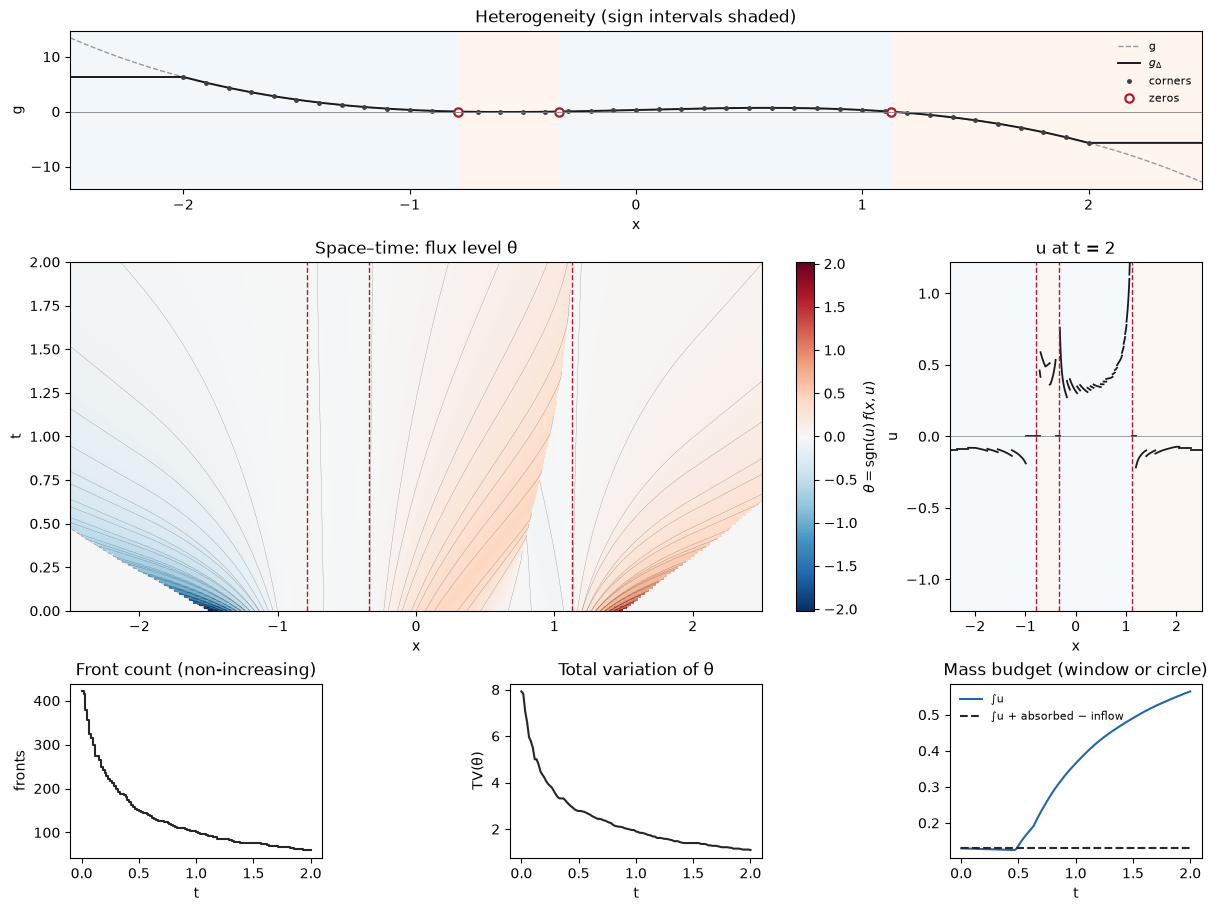

In [6]:
overview(history, exact_g=g)
plt.show()

## 4. Move through time
The slider selects saved frames; nothing is recomputed.

In [7]:
viewer = dashboard(history)
display(viewer)

Interactive widget: run this notebook in Jupyter or Colab to use it. Viewers without a kernel (GitHub, VS Code preview) cannot display it.


## 5. Snapshots of θ and u

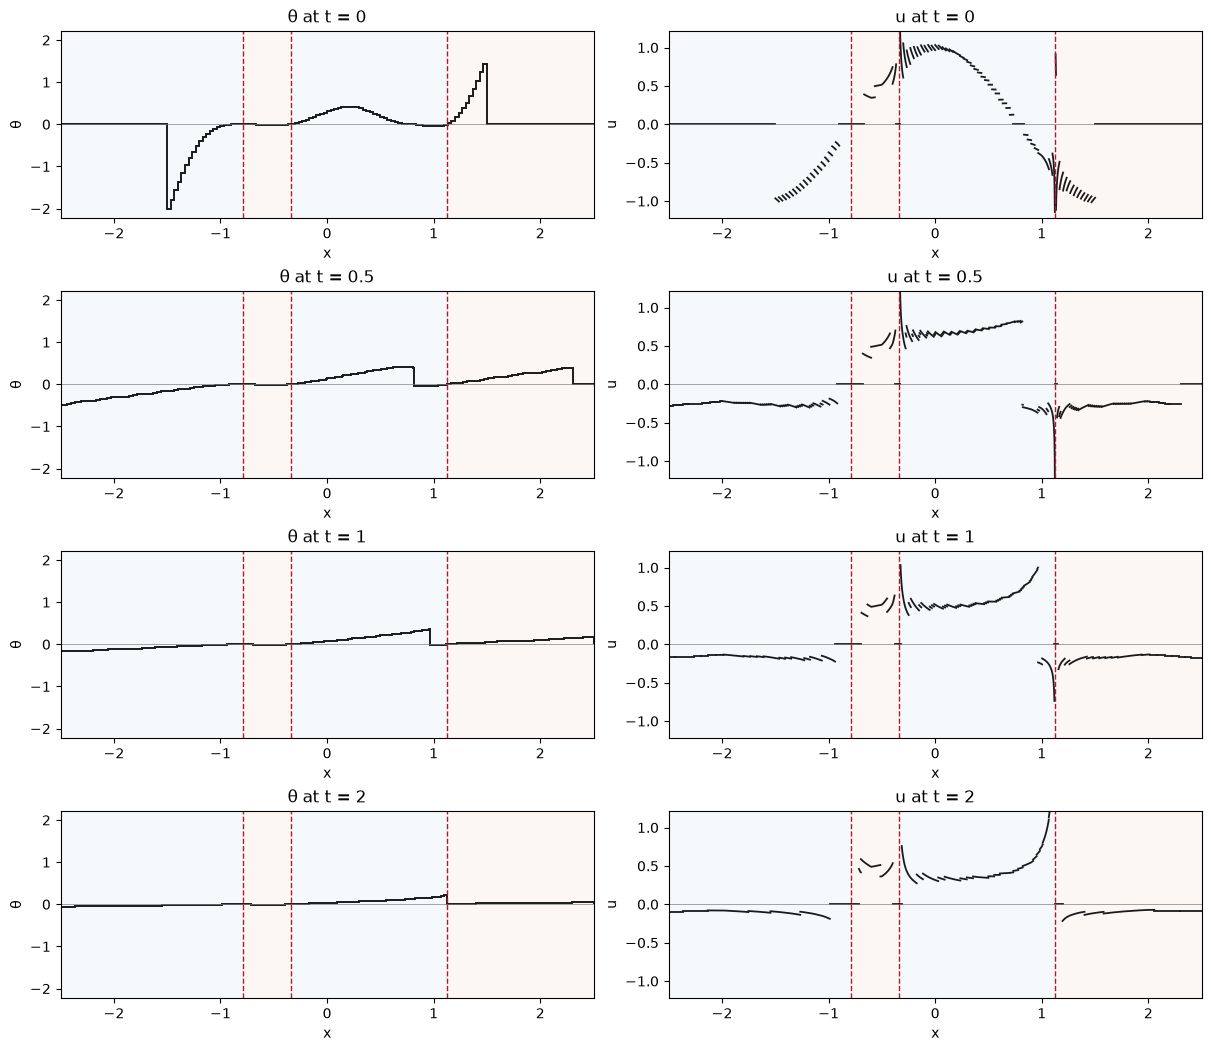

In [8]:
fig, axes = plt.subplots(len(snapshot_times), 2, figsize=(12, 2.6 * len(snapshot_times)),
                         constrained_layout=True, squeeze=False)
for row, t in zip(axes, snapshot_times):
    k = int(np.searchsorted(history.times, t))
    plot_profile(history, k, "theta", ax=row[0])
    plot_profile(history, k, "u", ax=row[1])
plt.show()

In [9]:
if periodic:
    fig, axes = plt.subplots(1, len(snapshot_times), figsize=(3.6 * len(snapshot_times), 3.6))
    for ax, t in zip(np.atleast_1d(axes), snapshot_times):
        plot_circle(history, int(np.searchsorted(history.times, t)), ax=ax)
    plt.show()
else:
    print("Set periodic = True to see θ drawn on the circle.")

Set periodic = True to see θ drawn on the circle.


## 6. Save figures and samples
Files go to `hetfront_exports/` beside the notebook; repeating the cell replaces them.

In [10]:
out = Path("hetfront_exports")
out.mkdir(exist_ok=True)
fig = overview(history, exact_g=g)
fig.savefig(out / "overview.png", dpi=160)
plt.close(fig)
np.savez_compressed(out / "solution.npz", x=history.x, times=history.times,
                    levels=history.levels, theta=history.theta, u=history.u,
                    delta=delta, power=power, nodes=g_delta.nodes, g_values=g_delta.values)
print(sorted(p.name for p in out.iterdir()))

['overview.png', 'solution.npz']
